# 05 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
from pathlib import Path
import sys

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_category_driver_pie_grid,
    save_interesting_si_plots,
    save_smoothed_si_screen_plots,
    select_existing_columns,
    summarize_smoothed_si_shapes,
    select_smoothed_si_shape_cases,
    select_decreasing_smoothed_si_trends,
    summarize_pair_publication_rates,
    summarize_pathogen_coverage,
)
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config


## Configuration


In [3]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.output_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.parquet_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
UNIFIED_DECISIONS_PATH = cfg_path(PIPELINE_CONFIG, "paths.unified_decisions", PROJECT_ROOT)
PATHOGEN_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
ANTIBIOTIC_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_coarsening", PROJECT_ROOT)
DRIVER_CATEGORY_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.driver_category_coarsening", PROJECT_ROOT)

# Analysis level controls antibiotic grouping for all SI model inputs and outputs.
ANTIBIOTIC_ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]
DECREASING_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "decreasing_smoothed_si_trends.parquet"
CONVEX_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "convex_u_shaped_smoothed_si_trends.parquet"
CONCAVE_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "concave_inverted_u_smoothed_si_trends.parquet"
DECREASING_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "decreasing_smoothed_si_plots"
CONVEX_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "convex_u_shaped_smoothed_si_plots"
CONCAVE_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "concave_inverted_u_smoothed_si_plots"

# Fit/rank window controls.
FIT_START_YEAR = cfg(PIPELINE_CONFIG, "si.fit_start_year")
FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.fit_end_year")
CURVE_FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.curve_fit_end_year")
NUM_FUTURE_YEARS = cfg(PIPELINE_CONFIG, "si.num_future_years")
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS

# Pair filtering and interesting-pair ranking thresholds.
MIN_AVG_AMR_PUBLICATIONS_PER_YEAR = cfg(PIPELINE_CONFIG, "si.min_avg_amr_publications_per_year")
MIN_CURRENT_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_current_predicted_count")
MIN_FUTURE_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_future_predicted_count")
MIN_SI_CHANGE = cfg(PIPELINE_CONFIG, "si.min_si_change")
MIN_POST_FIT_OBSERVED_YEARS = cfg(PIPELINE_CONFIG, "si.min_post_fit_observed_years")
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = cfg(PIPELINE_CONFIG, "si.max_post_fit_si_abs_pct_error_mean")
MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN = cfg(PIPELINE_CONFIG, "si.max_si_loess_residual_variance_mean")
FALLBACK_TOP_N = cfg(PIPELINE_CONFIG, "si.fallback_top_n")

# Driver plots and display controls.
CATEGORY_INCLUDE_DECISIONS = tuple(cfg(PIPELINE_CONFIG, "si.category_include_decisions"))
DRIVER_CATEGORY_LEVEL = cfg(PIPELINE_CONFIG, "si.driver_category_level")
DRIVER_LOOKBACK_YEARS = cfg(PIPELINE_CONFIG, "si.driver_lookback_years")
MAX_DRIVER_PLOTS = cfg(PIPELINE_CONFIG, "si.max_driver_plots")
DRIVER_PIE_GRID_COLUMNS = cfg(PIPELINE_CONFIG, "si.driver_pie_grid_columns")
MAX_INTERESTING_PLOTS = cfg(PIPELINE_CONFIG, "si.max_interesting_plots")
FIGURE_FORMAT = cfg(PIPELINE_CONFIG, "si.figure_format")
DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.display_plots")
MAX_DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.max_display_plots")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero")
LOESS_FRAC = cfg(PIPELINE_CONFIG, "si.loess_frac")
LOESS_DEGREE = cfg(PIPELINE_CONFIG, "si.loess_degree")
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
SHAPE_SCREEN_PLOT_COUNT = cfg(PIPELINE_CONFIG, "si.shape_screen_plot_count")


## Load Canonical Inputs


In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 23,250
yearly_screened unique pathogens: 158
yearly_screened unique antibiotics: 196
yearly_screened year range: 2000 - 2026
pathogen bg rows: 4,725
antibiotic bg rows: 5,346
unified decision rows available for driver analysis: 182,607


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [5]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 23,250
model pathogen-antibiotic rows: 4,246
model antibiotic values: 196
model antibiotic background rows: 5,346
model unified decision rows: 182,607


,pathogen,antibiotic,year,pmids,count
0,Achromobacter denitrificans,Amikacin,2026,[42414032],1
1,Achromobacter denitrificans,Aztreonam,2021,[33766786],1
2,Achromobacter denitrificans,Cefiderocol,2022,[35029278],1
3,Achromobacter denitrificans,Cefiderocol,2026,[41586494],1
4,Achromobacter denitrificans,Ceftazidime,2022,[35029278],1
5,Achromobacter denitrificans,Ceftazidime,2026,[41586494],1
6,Achromobacter denitrificans,Ceftazidime/avibactam,2026,[41586494],1
7,Achromobacter denitrificans,Ciprofloxacin,2013,[22944724],1
8,Achromobacter denitrificans,Ciprofloxacin,2021,[33766786],1
9,Achromobacter denitrificans,Ciprofloxacin,2022,[35029278],1


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [6]:
yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()

yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    min_avg_amr_publications_per_year=MIN_AVG_AMR_PUBLICATIONS_PER_YEAR,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)

display(pathogen_filter_summary_df.query("status != 'present_in_both'"))
summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 298 / 4,246 pairs with >= 1 publications/year on average from 2000 to 2023.
model input before publication filter pathogens: 158
model input after publication filter pathogens: 34
Pathogens present in model input before publication filter but absent from model input after publication filter: 124
Achromobacter denitrificans, Achromobacter xylosoxidans, Acinetobacter calcoaceticus, Actinotignum schaalii, Aeromonas caviae, Aeromonas hydrophila, Aeromonas sobria, Aeromonas veronii, Aggregatibacter actinomycetemcomitans, Bacillus anthracis, Bacillus cereus, Bartonella bacilliformis, Bartonella quintana, Bordetella bronchiseptica, Bordetella parapertussis, Bordetella pertussis, Borrelia burgdorferi, Brucella melitensis, Burkholderia cenocepacia, Burkholderia cepacia, Burkholderia multivorans, Burkholderia pseudomallei, Campylobacter fetus, Chlamydia pneumoniae, Chlamydia psittaci, Chlamydia trachomatis, Chromobacterium violaceum, Chryseobacterium indologenes, Cit

,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Achromobacter denitrificans,20,21,12,0.0,0.0,0.0,True,False,missing_from_modeled
1,Achromobacter xylosoxidans,44,50,24,0.0,0.0,0.0,True,False,missing_from_modeled
2,Acinetobacter calcoaceticus,35,35,19,0.0,0.0,0.0,True,False,missing_from_modeled
3,Actinotignum schaalii,11,11,11,0.0,0.0,0.0,True,False,missing_from_modeled
4,Aeromonas caviae,32,35,22,0.0,0.0,0.0,True,False,missing_from_modeled
...,...,...,...,...,...,...,...,...,...,...
119,Vibrio alginolyticus,43,46,20,0.0,0.0,0.0,True,False,missing_from_modeled
120,Vibrio fluvialis,20,20,15,0.0,0.0,0.0,True,False,missing_from_modeled
121,Vibrio vulnificus,28,28,16,0.0,0.0,0.0,True,False,missing_from_modeled
122,Yersinia pestis,19,10,9,0.0,0.0,0.0,True,False,missing_from_modeled


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
2927,Staphylococcus aureus,Meticillin,2875,119.791667
1201,Escherichia coli,Ampicillin,984,41.000000
2982,Staphylococcus aureus,Vancomycin,706,29.416667
1346,Escherichia coli,Tetracycline,661,27.541667
1249,Escherichia coli,Ciprofloxacin,645,26.875000
1504,Helicobacter pylori,Clarithromycin,630,26.250000
1519,Helicobacter pylori,Metronidazole,486,20.250000
1254,Escherichia coli,Colistin,460,19.166667
2942,Staphylococcus aureus,Oxacillin,458,19.083333
2907,Staphylococcus aureus,Erythromycin,417,17.375000


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [7]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))
si_df.head(10)


SI rows: 6,963
SI pairs: 298
SI pathogens: 34
filtered model input pathogens: 34
yearly SI output pathogens: 34


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14748260]",2,80,183,0.477121,1.908485,2.264818,0.156653,0.434344,0.320468
1,Acinetobacter baumannii,Amikacin,2005,"[16103700, 16258323]",2,139,187,0.477121,2.146128,2.274158,0.244708,0.756740,0.232414
2,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2,176,194,0.477121,2.247973,2.290035,0.288038,0.941055,0.189084
3,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18792817]",2,247,228,0.477121,2.394452,2.359835,0.372481,1.357659,0.104640
4,Acinetobacter baumannii,Amikacin,2009,[19795613],1,287,256,0.301030,2.459392,2.409933,0.418940,1.623856,-0.117910
5,Acinetobacter baumannii,Amikacin,2010,"[20107089, 20194701, 20499531, 20921306, 21137...",5,342,265,0.778151,2.535294,2.424882,0.452700,1.835962,0.325451
6,Acinetobacter baumannii,Amikacin,2011,[22016680],1,421,266,0.301030,2.625312,2.426511,0.485156,2.056019,-0.184126
7,Acinetobacter baumannii,Amikacin,2012,"[22104303, 22154196, 22461312, 22579564, 22808...",6,495,294,0.845098,2.695482,2.469822,0.530259,2.390461,0.314839
8,Acinetobacter baumannii,Amikacin,2013,"[23400749, 23435692, 23660097, 23668462, 23676...",9,511,368,1.000000,2.709270,2.567026,0.580901,2.809791,0.419099
9,Acinetobacter baumannii,Amikacin,2014,"[24235096, 24607428, 24653812, 25241558, 25336...",6,640,394,0.845098,2.806858,2.596597,0.629183,3.257782,0.215915


## Rank Reliable Future High-Interest Pairs


In [8]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    max_si_loess_residual_variance_mean=MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/298] ranking Acinetobacter baumannii vs Amikacin


[2/298] ranking Acinetobacter baumannii vs Ampicillin
[3/298] ranking Acinetobacter baumannii vs Ampicillin/sulbactam
[4/298] ranking Acinetobacter baumannii vs Cefepime
[5/298] ranking Acinetobacter baumannii vs Cefotaxime
[6/298] ranking Acinetobacter baumannii vs Ceftazidime
[7/298] ranking Acinetobacter baumannii vs Ceftriaxone
[8/298] ranking Acinetobacter baumannii vs Ciprofloxacin
[9/298] ranking Acinetobacter baumannii vs Colistin
[10/298] ranking Acinetobacter baumannii vs Gentamicin
[11/298] ranking Acinetobacter baumannii vs Meropenem
[12/298] ranking Acinetobacter baumannii vs Minocycline
[13/298] ranking Acinetobacter baumannii vs Piperacillin
[14/298] ranking Acinetobacter baumannii vs Polymyxin-B
[15/298] ranking Acinetobacter baumannii vs Sulbactam
[16/298] ranking Acinetobacter baumannii vs Tetracycline
[17/298] ranking Acinetobacter baumannii vs Tigecycline
[18/298] ranking Acinetobacter baumannii vs Tobramycin
[19/298] ranking Bacteroides fragilis vs Clindamycin
[20/

,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Piperacillin,0.260840,0.619995,11.918351,76.625423,0.052303,41.410820
1,Klebsiella pneumoniae,Ceftazidime,0.193940,0.321989,37.369986,124.998531,0.042149,1.671788
2,Klebsiella pneumoniae,Colistin,0.153366,0.247968,61.511490,138.764905,0.012812,7.275880
3,Klebsiella pneumoniae,Meropenem,0.133438,0.221195,51.882282,134.218573,0.015530,8.499044
4,Staphylococcus aureus,Meticillin,0.122107,0.162382,404.202506,704.574883,0.003082,5.627232
5,Staphylococcus aureus,Cefoxitin,0.114308,0.199987,32.843018,65.377829,0.014028,9.008250
6,Mycobacterium tuberculosis,Rifampicin,0.095289,0.181508,19.113887,34.132058,0.025781,13.110564
7,Klebsiella pneumoniae,Ampicillin,0.092030,0.214356,16.102078,38.682470,0.037252,43.983413
8,Klebsiella pneumoniae,Ertapenem,0.090953,0.216379,13.658697,30.402344,0.016019,44.170243
9,Escherichia coli,Tigecycline,0.089523,0.196600,15.036173,29.850453,0.017532,33.148631


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [9]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_target_pair_supported_share
0,Klebsiella pneumoniae,Piperacillin,0.260840,0.619995,11.918351,76.625423,21,6,SURVEILLANCE,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
1,Klebsiella pneumoniae,Ceftazidime,0.193940,0.321989,37.369986,124.998531,82,52,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
2,Klebsiella pneumoniae,Colistin,0.153366,0.247968,61.511490,138.764905,166,109,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,SURVEILLANCE,0.000000,1.0
3,Klebsiella pneumoniae,Meropenem,0.133438,0.221195,51.882282,134.218573,130,79,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
4,Staphylococcus aureus,Meticillin,0.122107,0.162382,404.202506,704.574883,1271,485,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000787,1.0
5,Staphylococcus aureus,Cefoxitin,0.114308,0.199987,32.843018,65.377829,99,53,SURVEILLANCE,SURVEILLANCE,0.000000,1.0
6,Mycobacterium tuberculosis,Rifampicin,0.095289,0.181508,19.113887,34.132058,55,15,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,OTHER,0.000000,1.0
7,Klebsiella pneumoniae,Ampicillin,0.092030,0.214356,16.102078,38.682470,41,24,SURVEILLANCE,SURVEILLANCE,0.000000,1.0
8,Klebsiella pneumoniae,Ertapenem,0.090953,0.216379,13.658697,30.402344,40,18,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
9,Escherichia coli,Tigecycline,0.089523,0.196600,15.036173,29.850453,46,31,SURVEILLANCE,SURVEILLANCE,0.000000,1.0


## Plot Category Driver Curves


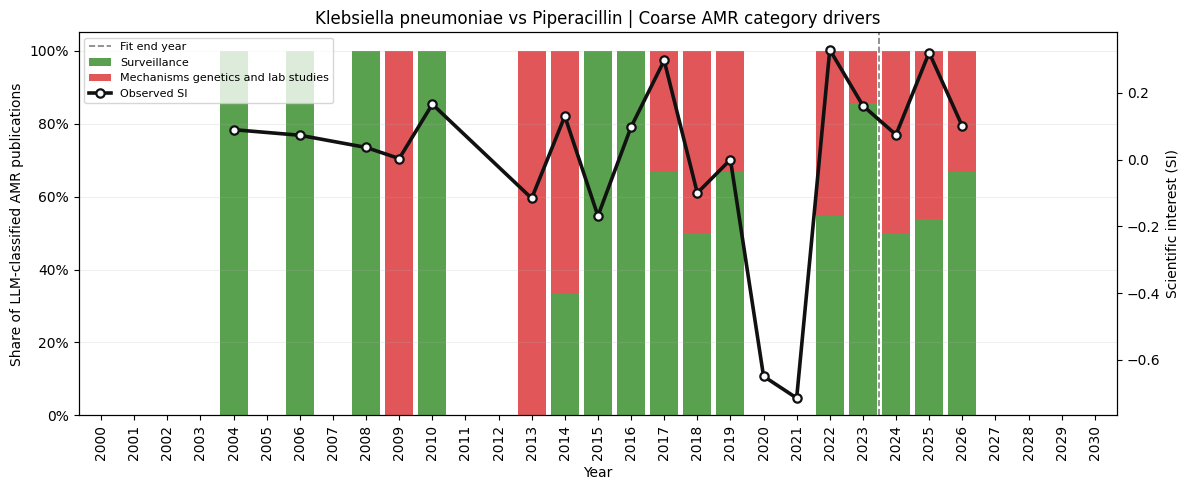

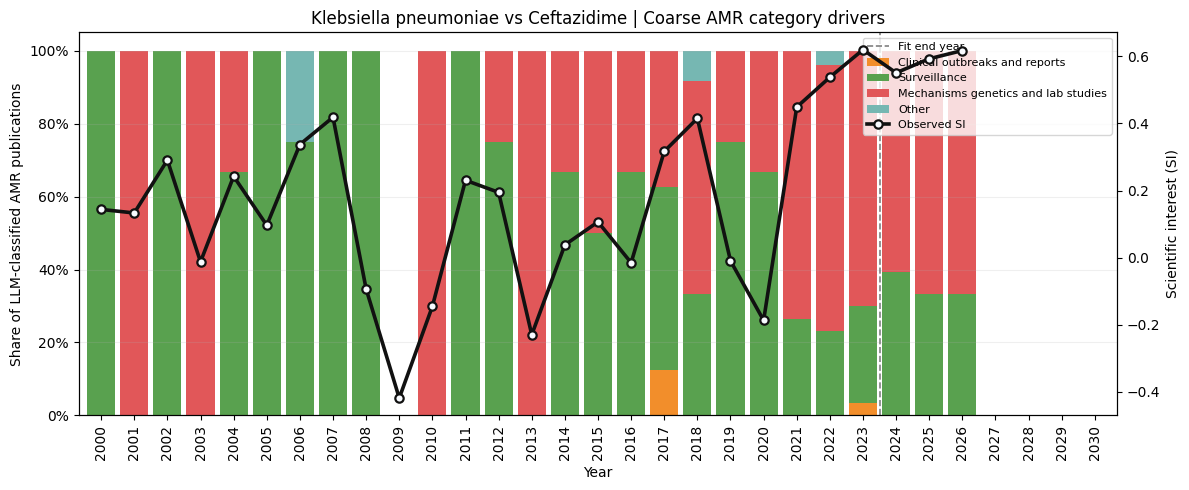

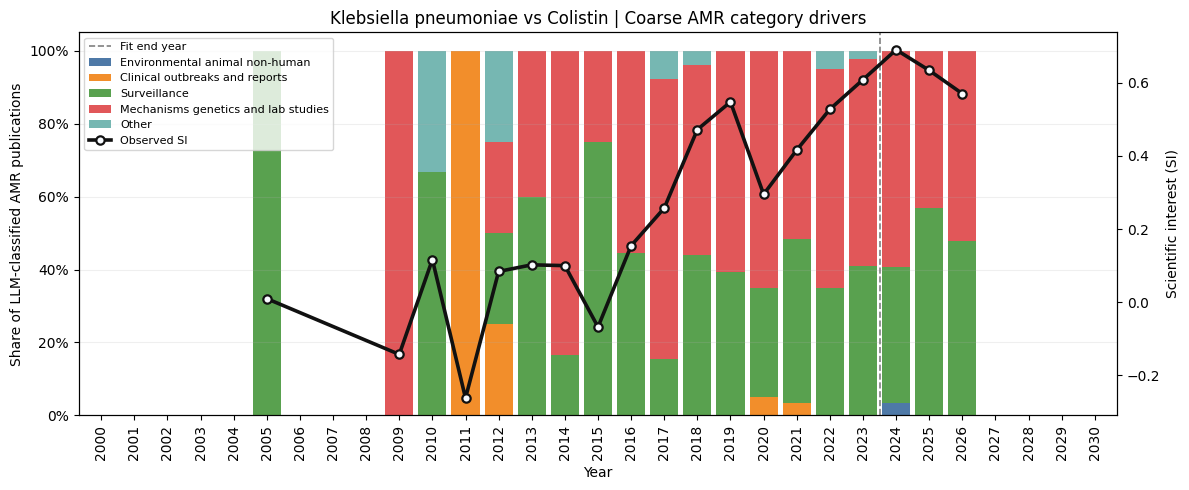

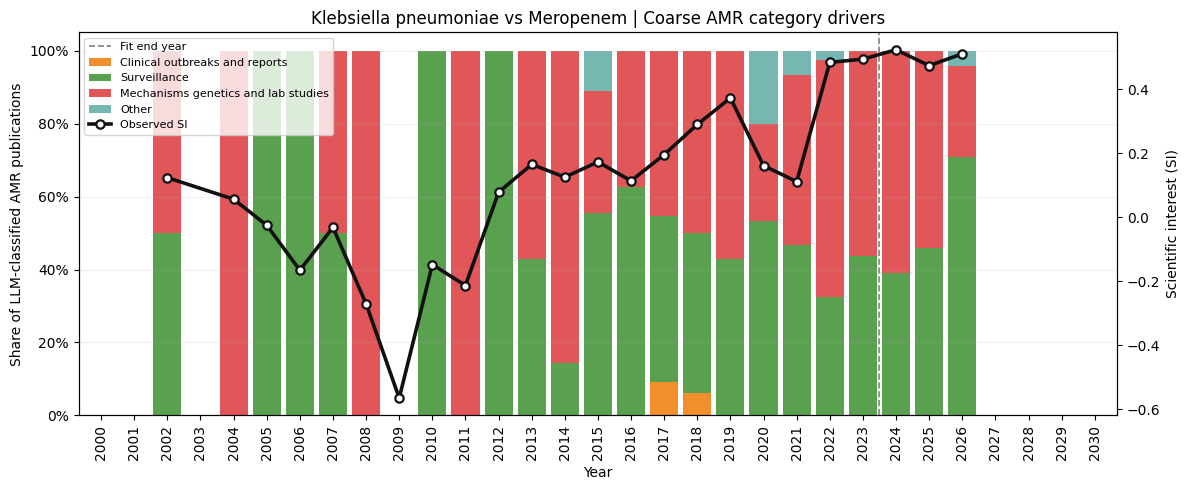

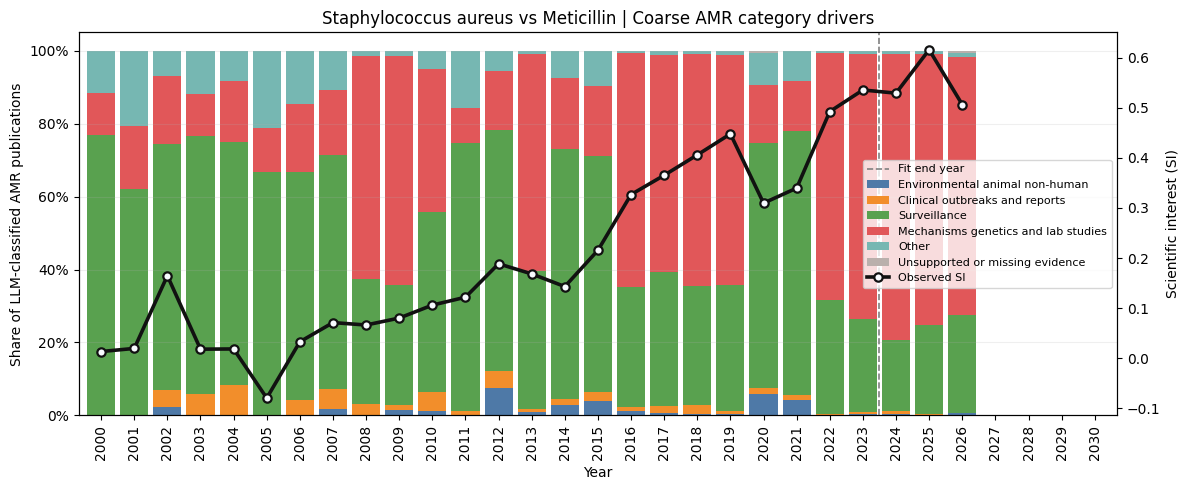

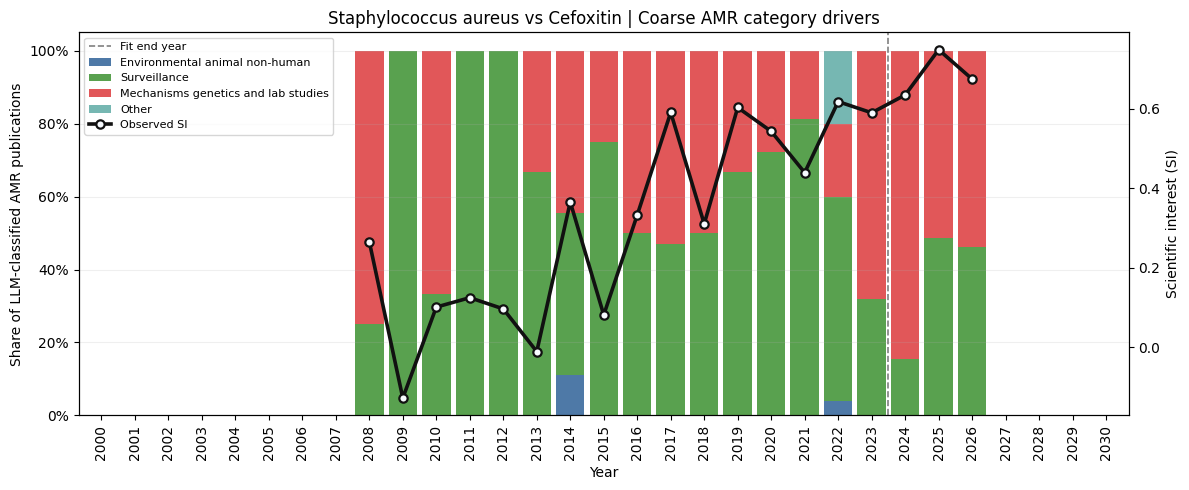

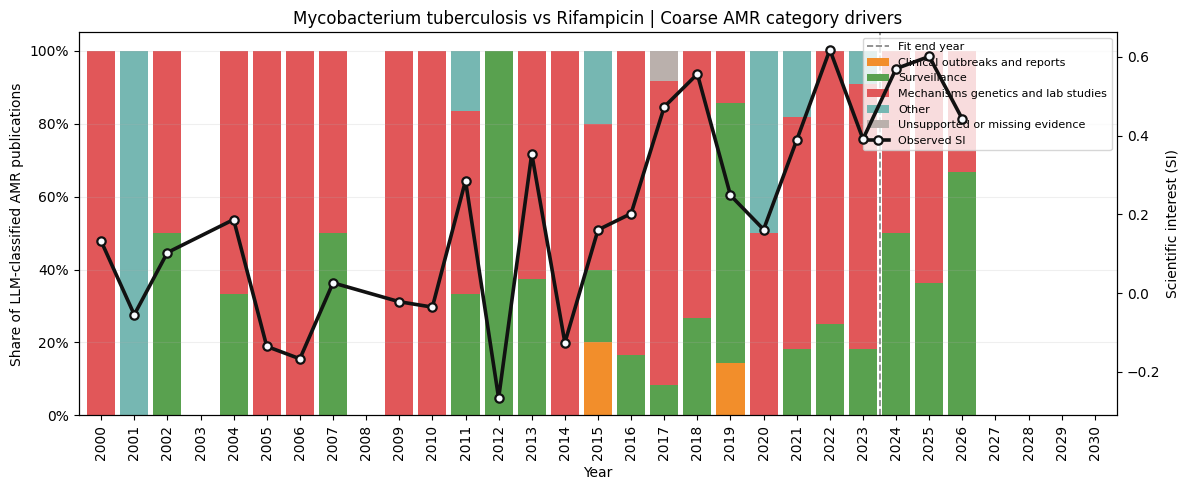

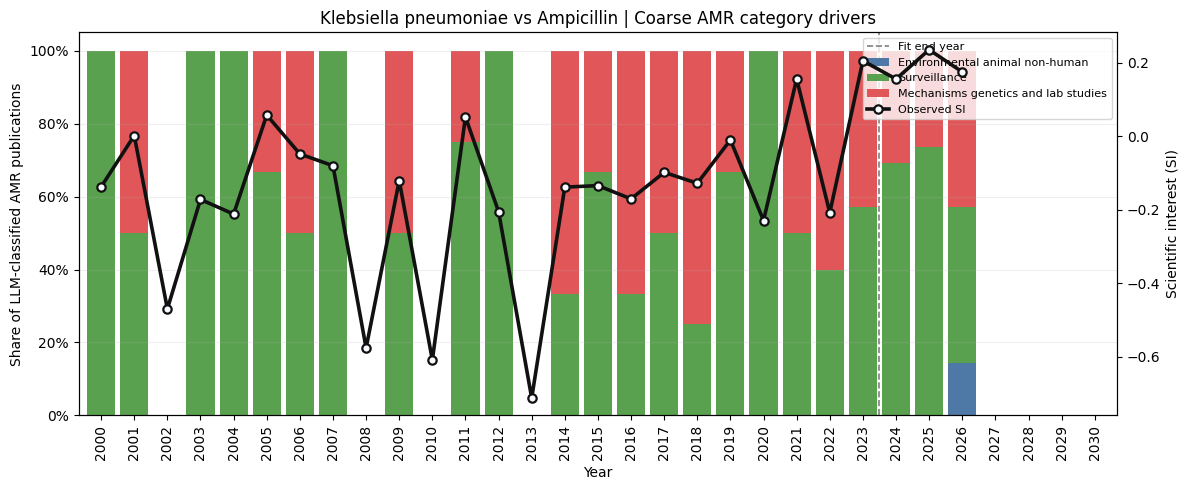

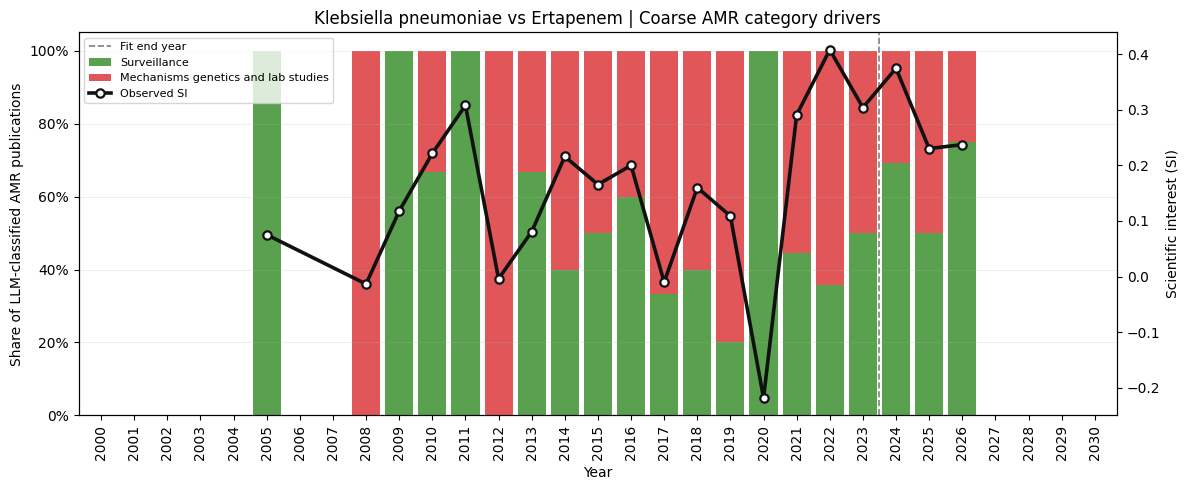

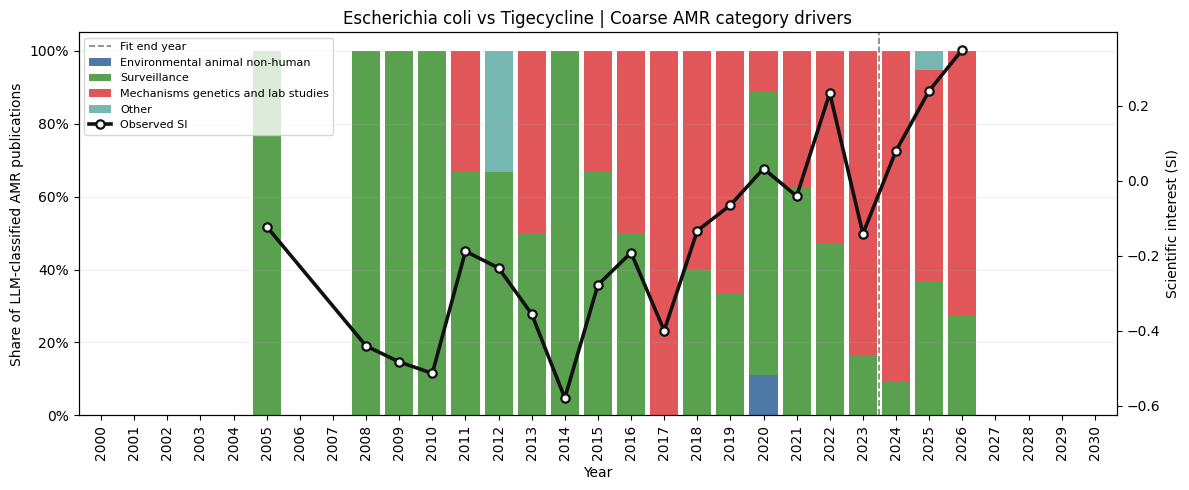

Saved 25 coarse category driver plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 10 category driver plots inline.
Saved all-year category driver pie grid for 47 pairs to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots/all_pairs_category_driver_pie_grid.pdf
Saved all-pair driver pie charts: 47 pairs -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots/all_pairs_category_driver_pie_grid.pdf


In [10]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

driver_pie_grid_path = DRIVER_PLOT_DIR / "all_pairs_category_driver_pie_grid.pdf"
saved_driver_pie_pairs = save_category_driver_pie_grid(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_path=driver_pie_grid_path,
    num_columns=DRIVER_PIE_GRID_COLUMNS,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    verbose=True,
)
print(f"Saved all-pair driver pie charts: {saved_driver_pie_pairs:,} pairs -> {driver_pie_grid_path}")


## Plot Top Interesting Pairs


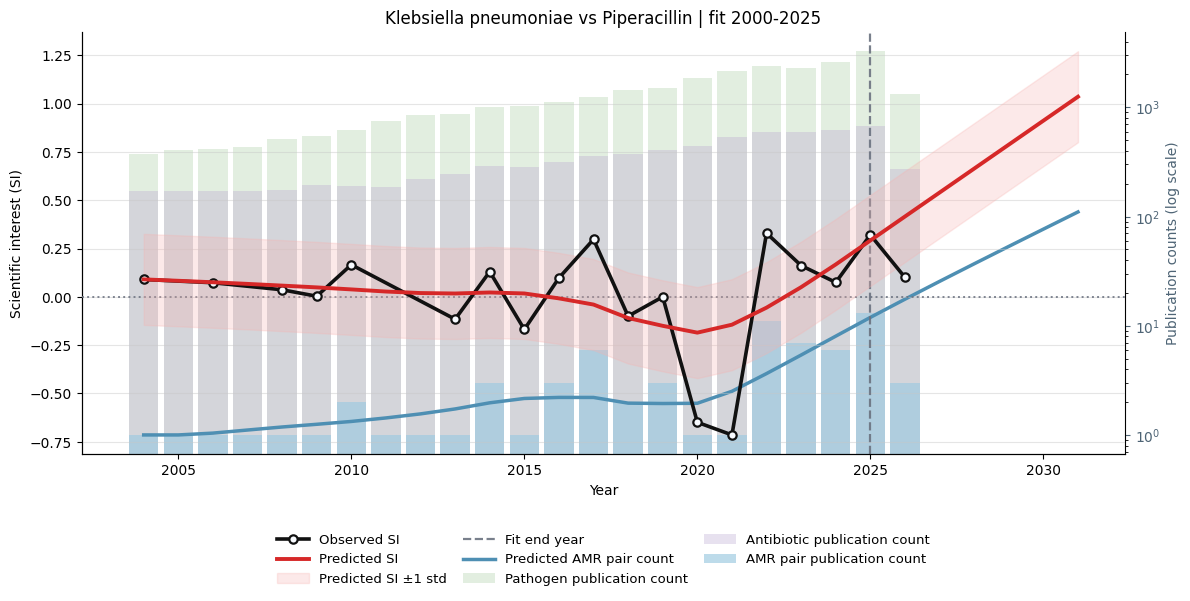

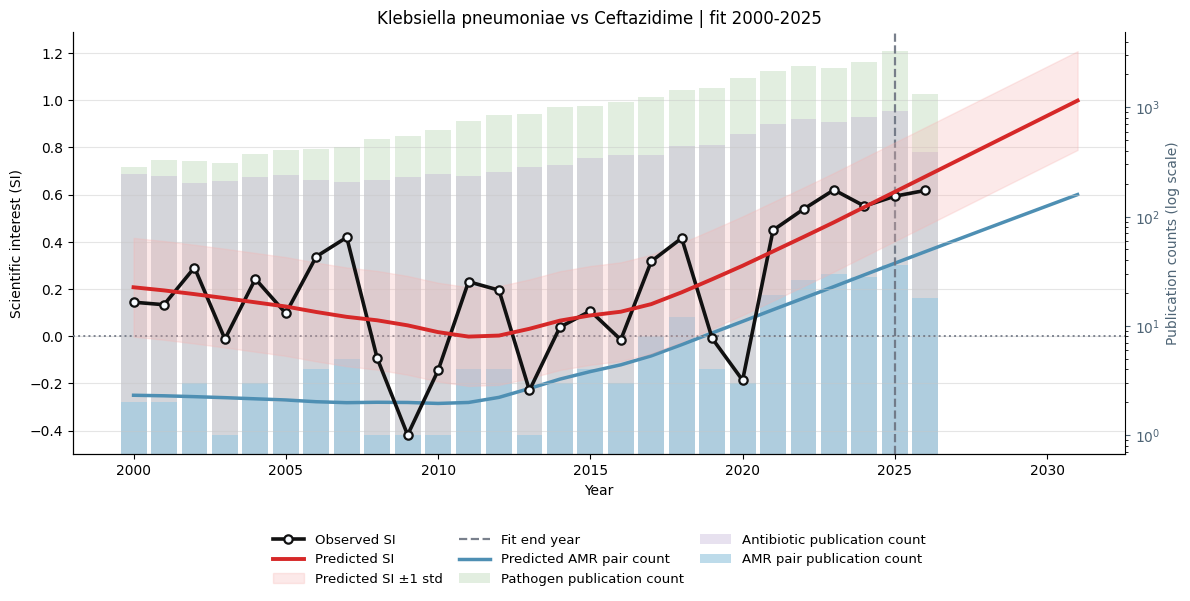

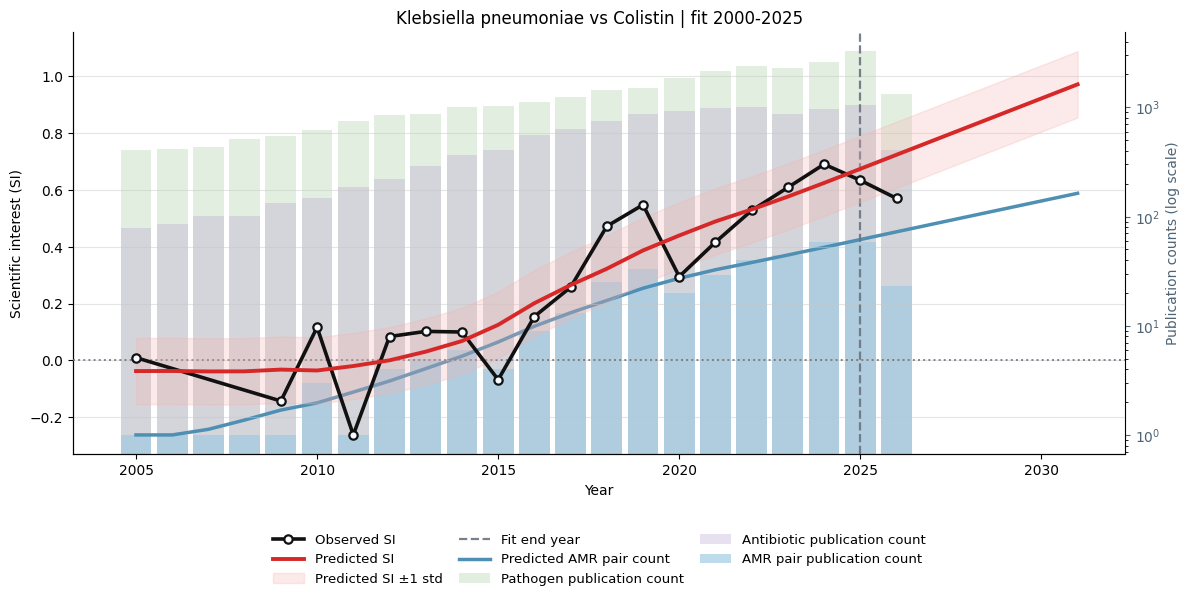

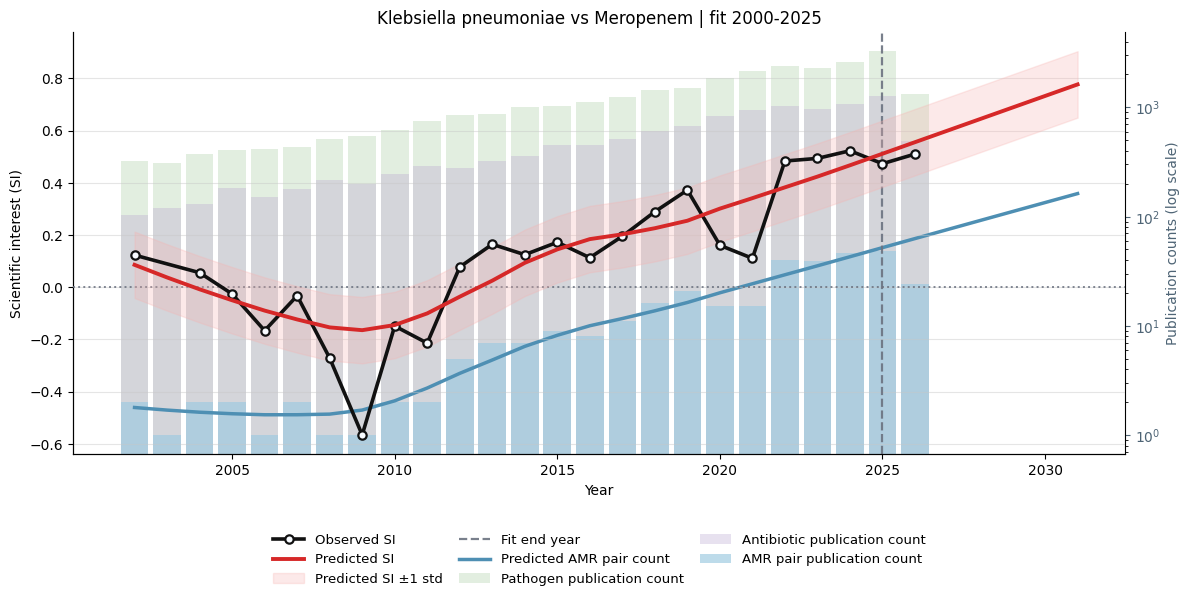

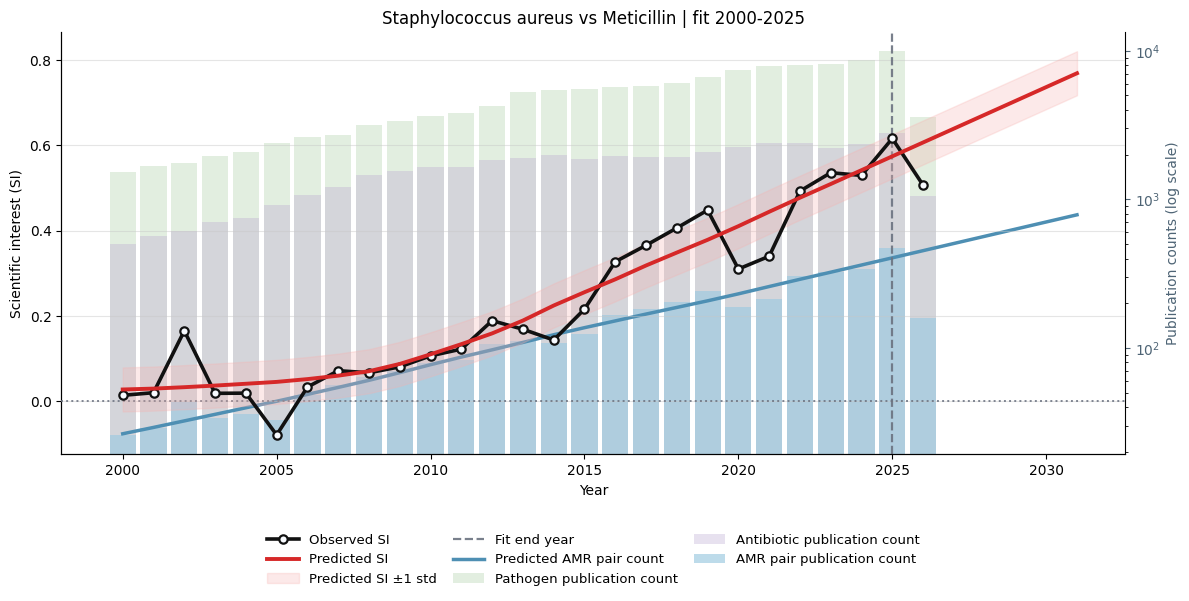

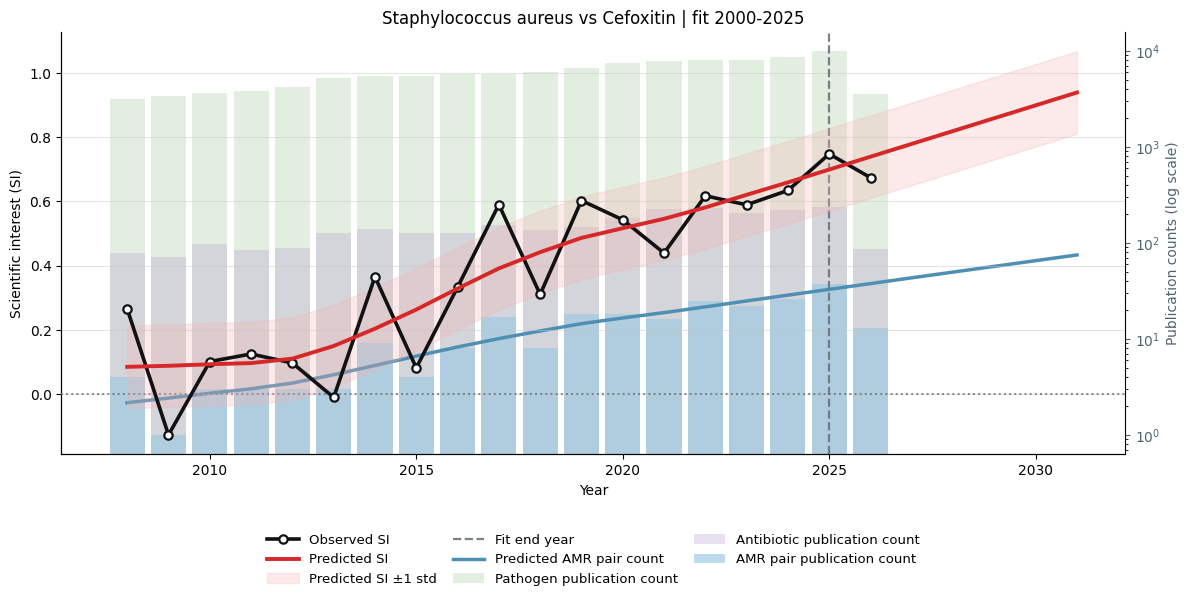

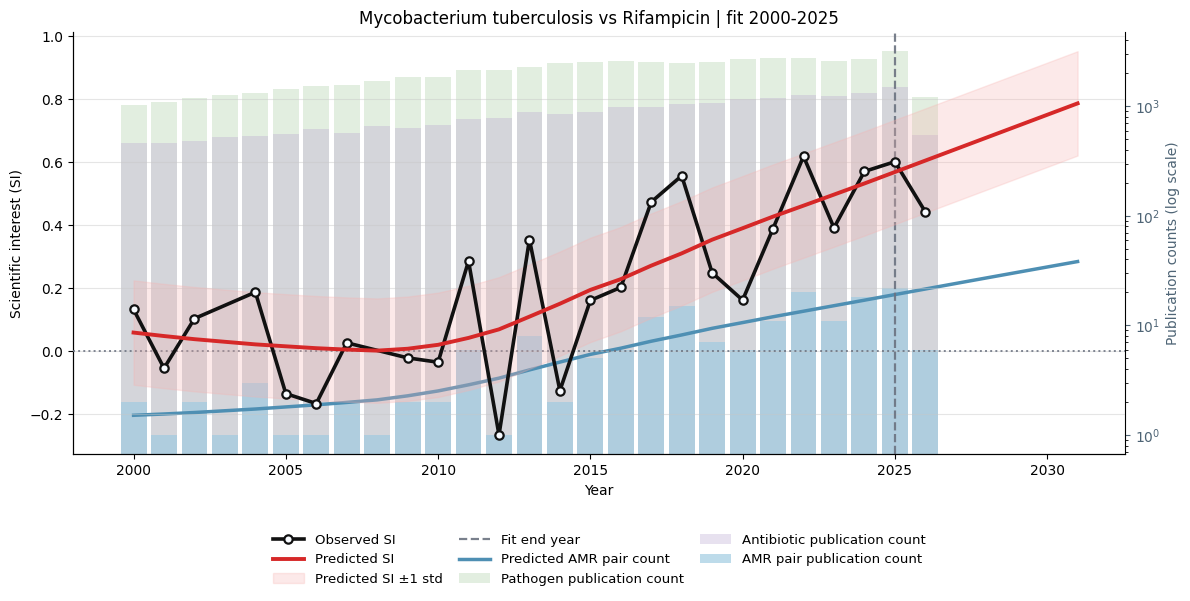

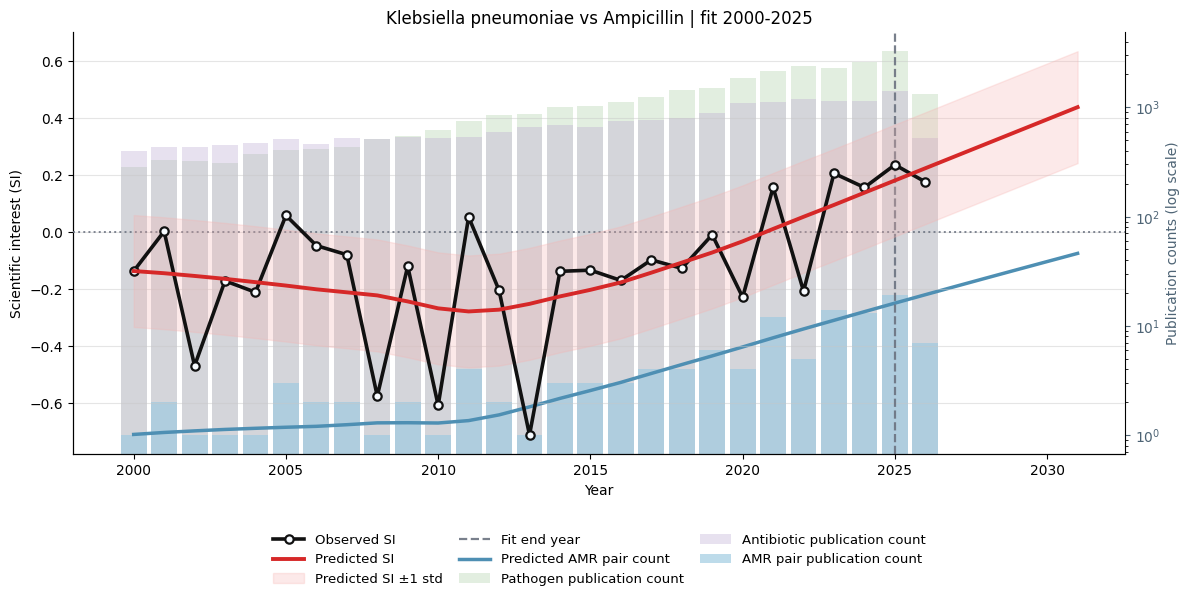

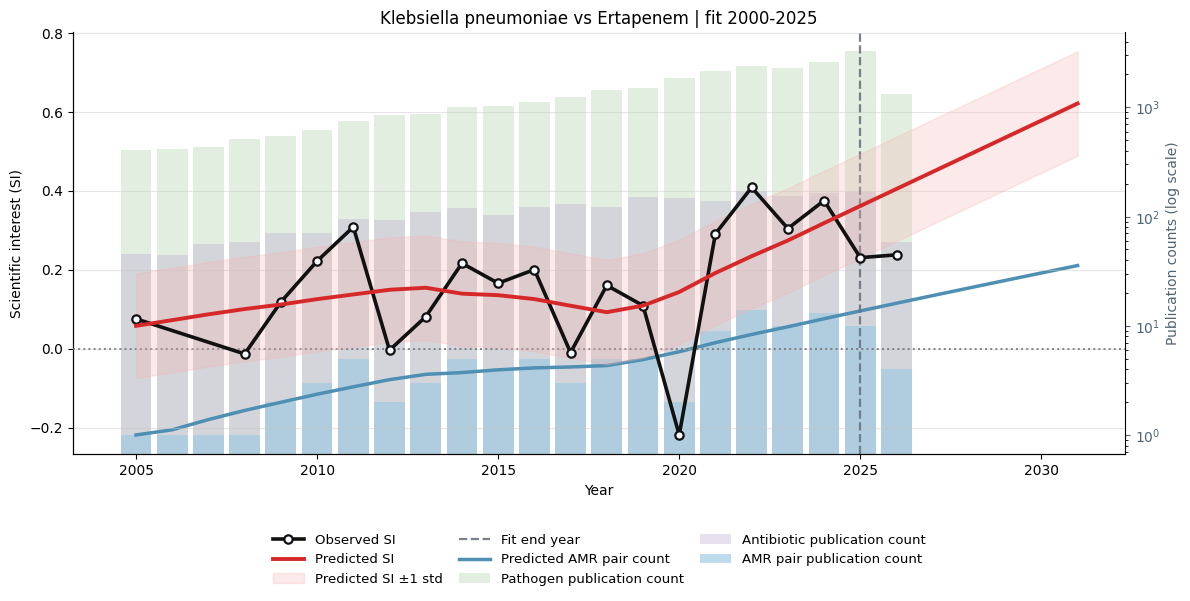

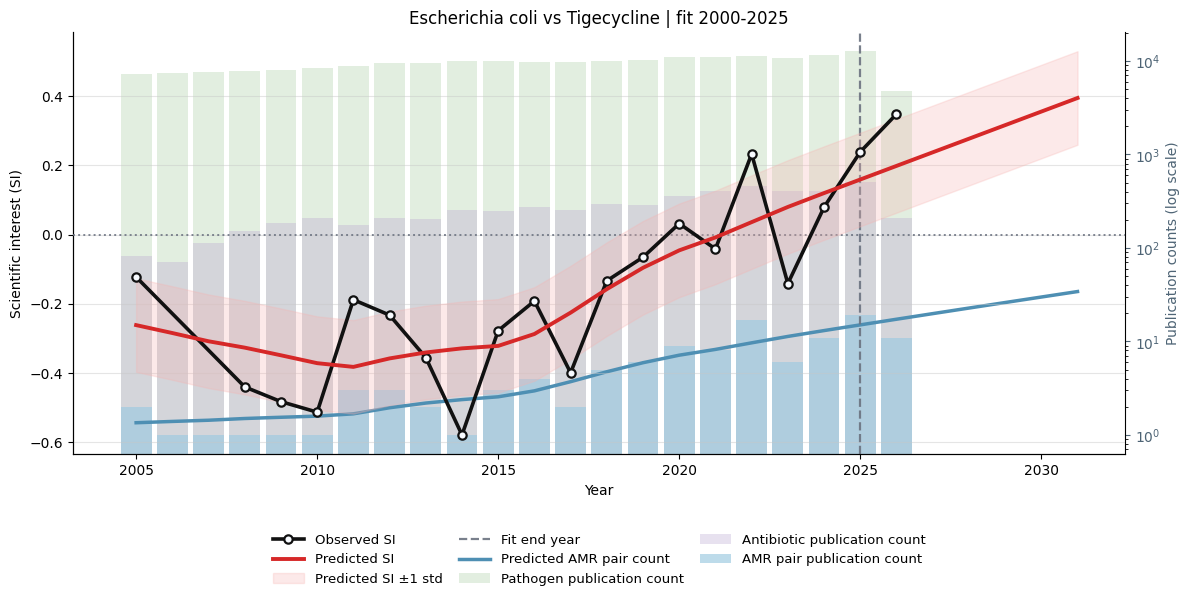

Saved 25 plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 10 plots inline.


In [11]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Additional SI Shape Screens


### Largest Decreasing Smoothed SI Trends


In [12]:
decreasing_smoothed_si_df = select_decreasing_smoothed_si_trends(
    rank_df,
    output_path=DECREASING_SI_OUTPUT_PATH,
)

select_existing_columns(
    decreasing_smoothed_si_df,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    head=10,
)


Saved decreasing smoothed SI table: 143 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/decreasing_smoothed_si_trends.parquet


,pathogen,antibiotic,reference_year,future_year,current_predicted_SI,future_predicted_SI,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Vibrio parahaemolyticus,Ampicillin,2025,2030,-0.196472,-0.681799,-0.485327,2.557172,0.412440,0.051361,96.669674
1,Mycoplasmoides genitalium,Moxifloxacin,2025,2030,-0.016662,-0.370645,-0.353984,3.443008,1.279694,0.010656,2376.267185
2,Salmonella enterica,Cefoxitin,2025,2030,-0.583192,-0.926314,-0.343122,0.382873,0.000000,0.022773,30.141056
3,Campylobacter jejuni,Chloramphenicol,2025,2030,-0.542305,-0.877707,-0.335402,0.138593,0.000000,0.043228,37.218119
4,Acinetobacter baumannii,Tobramycin,2025,2030,-0.131847,-0.456070,-0.324223,1.679344,0.628213,0.023608,230.526003
5,Cutibacterium acnes,Tetracycline,2025,2030,-0.328763,-0.639714,-0.310950,0.855488,0.201279,0.029604,109.247098
6,Staphylococcus aureus,Dalfopristin/quinupristin,2025,2030,-0.455829,-0.765209,-0.309380,0.098339,0.000000,0.043307,39.509442
7,Staphylococcus aureus,Tigecycline,2025,2030,-0.582537,-0.890415,-0.307878,1.645224,0.698144,0.052408,133.502193
8,Shigella flexneri,Chloramphenicol,2025,2030,-0.399277,-0.699479,-0.300202,0.128116,0.000000,0.025543,NaN
9,Clostridioides difficile,Moxifloxacin,2025,2030,0.173758,-0.124966,-0.298723,2.502179,0.911238,0.036552,383.857504


### Most Convex and Concave Smoothed SI Curves


In [13]:
smoothed_si_shape_df = summarize_smoothed_si_shapes(
    rank_df,
    si_df,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
)

most_convex_smoothed_si_df, most_concave_smoothed_si_df = select_smoothed_si_shape_cases(
    smoothed_si_shape_df,
    top_n=10,
    convex_output_path=CONVEX_SI_OUTPUT_PATH,
    concave_output_path=CONCAVE_SI_OUTPUT_PATH,
)

print("Most convex U-shaped smoothed SI curves")
select_existing_columns(
    most_convex_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)

print("Most concave inverted-U smoothed SI curves")
select_existing_columns(
    most_concave_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)


Saved convex U-shaped smoothed SI table: 10 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/convex_u_shaped_smoothed_si_trends.parquet
Saved concave inverted-U smoothed SI table: 10 rows -> /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/parquets/concave_inverted_u_smoothed_si_trends.parquet
Most convex U-shaped smoothed SI curves
Most concave inverted-U smoothed SI curves


,pathogen,antibiotic,shape_start_year,shape_midpoint_year,curve_fit_end_year,shape_end_year,start_predicted_SI,midpoint_predicted_SI,end_predicted_SI,endpoint_balance_abs_diff,convex_u_score,concave_cap_score,si_quadratic_coef,si_quadratic_r2,si_change,si_loess_residual_variance_mean
0,Campylobacter jejuni,Chloramphenicol,2002,2016,2025,2030,-0.218701,-0.036655,-0.877707,0.659005,-0.511549,0.511549,-0.002547,0.960486,-0.335402,0.043228
1,Vibrio parahaemolyticus,Ampicillin,2011,2020,2025,2030,-0.004413,0.121084,-0.681799,0.677386,-0.464190,0.464190,-0.004944,0.909750,-0.485327,0.051361
2,Enterococcus faecium,Tetracycline,2000,2015,2025,2030,-0.166371,0.001690,-0.701858,0.535488,-0.435804,0.435804,-0.001921,0.967933,-0.244498,0.032618
3,Neisseria gonorrhoeae,Azithromycin,2001,2016,2025,2030,-0.302575,0.313618,0.123702,0.426277,-0.403054,0.403054,-0.001745,0.911133,-0.125747,0.015418
4,Klebsiella pneumoniae,Ceftazidime/avibactam,2015,2022,2025,2030,-0.457158,0.382792,0.457319,0.914477,-0.382711,0.382711,-0.006734,0.961657,0.026073,0.015003
5,Shigella flexneri,Chloramphenicol,2000,2014,2025,2028,0.102798,0.141844,-0.579398,0.682196,-0.380144,0.380144,-0.001880,0.990405,-0.300202,0.025543
6,Escherichia coli,Kanamycin,2001,2016,2025,2030,-0.024533,0.054942,-0.597018,0.572485,-0.365718,0.365718,-0.001802,0.985308,-0.273428,0.036218
7,Staphylococcus aureus,Tigecycline,2005,2018,2025,2030,-0.058470,-0.109120,-0.890415,0.831945,-0.365322,0.365322,-0.002164,0.945075,-0.307878,0.052408
8,Enterococcus faecalis,Erythromycin,2000,2015,2025,2030,-0.148103,0.104125,-0.352038,0.203935,-0.354196,0.354196,-0.001574,0.966408,-0.207501,0.032996
9,Pseudomonas aeruginosa,Ceftazidime/avibactam,2015,2022,2025,2030,-0.602749,-0.103602,-0.308054,0.294695,-0.351800,0.351800,-0.006121,0.894566,-0.164140,0.006262


### Plots for Additional SI Shape Screens


In [14]:
# SHAPE_SCREEN_PLOT_COUNT is loaded from PIPELINE_CONFIG in the main config cell.


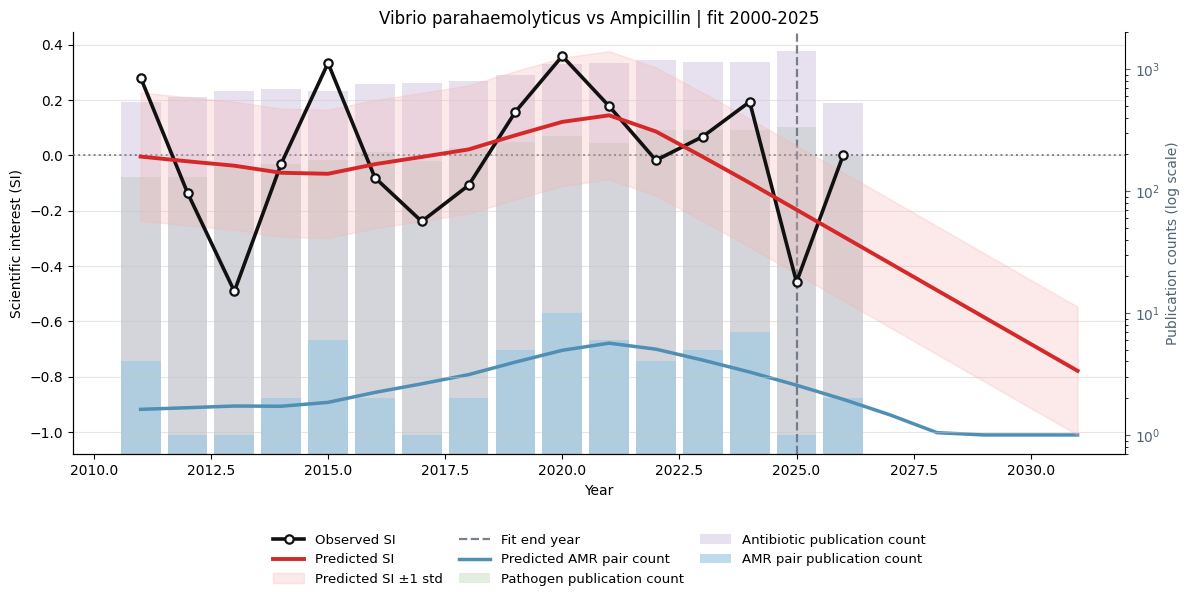

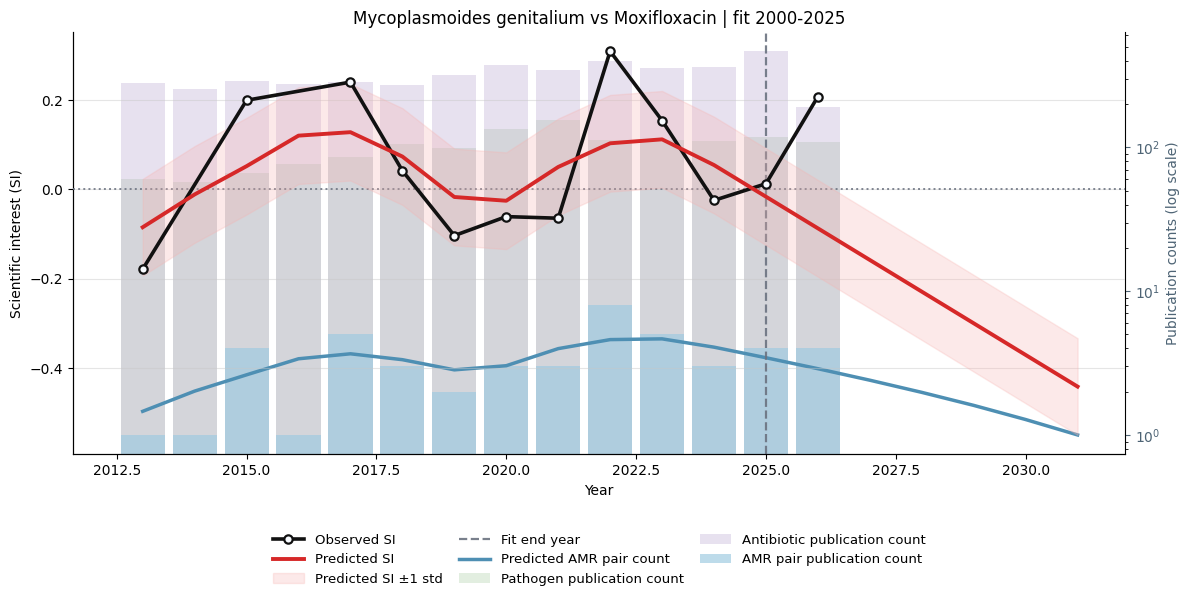

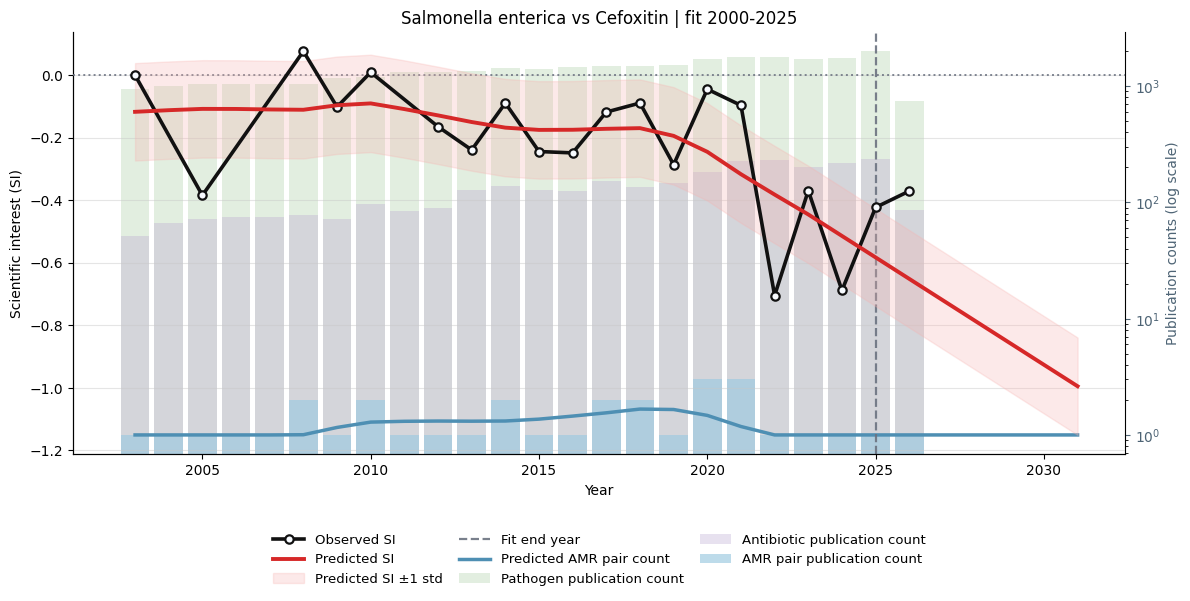

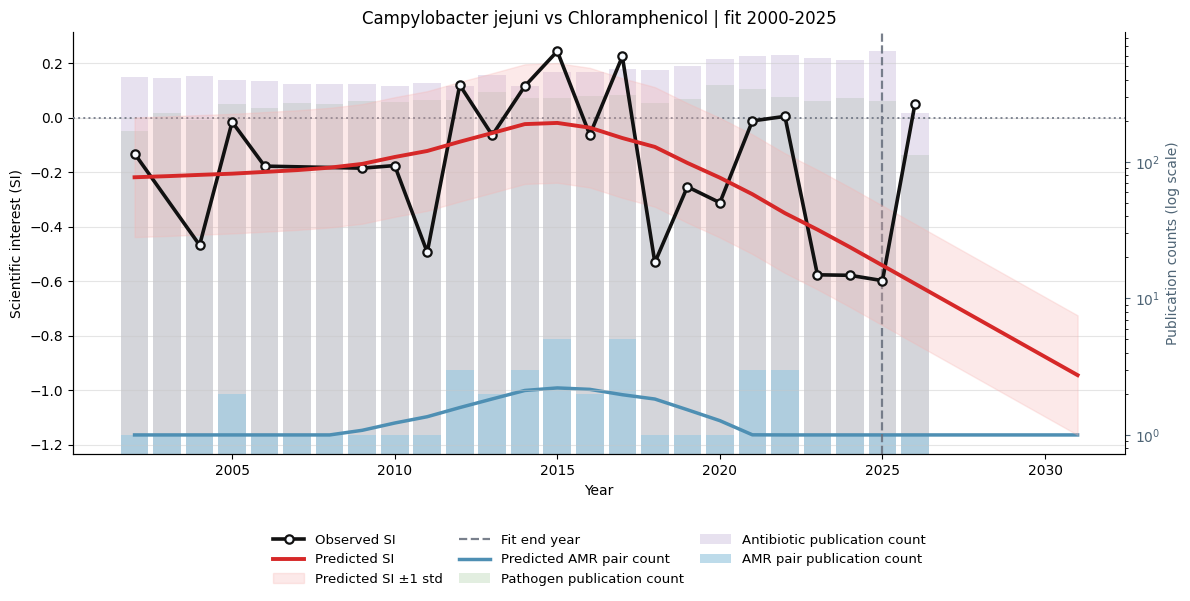

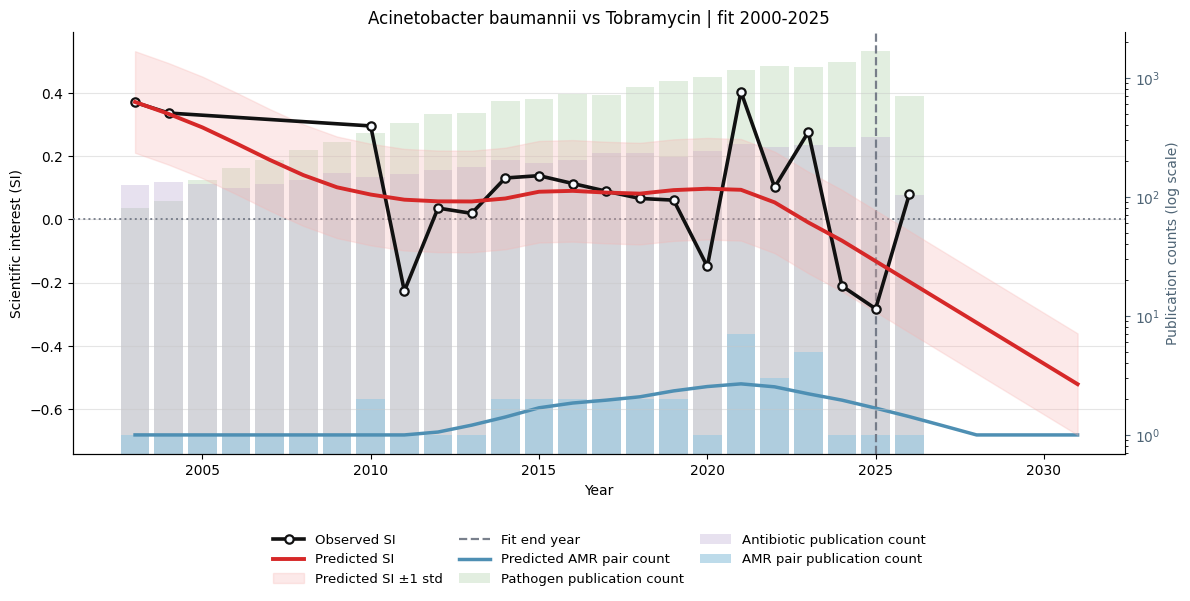

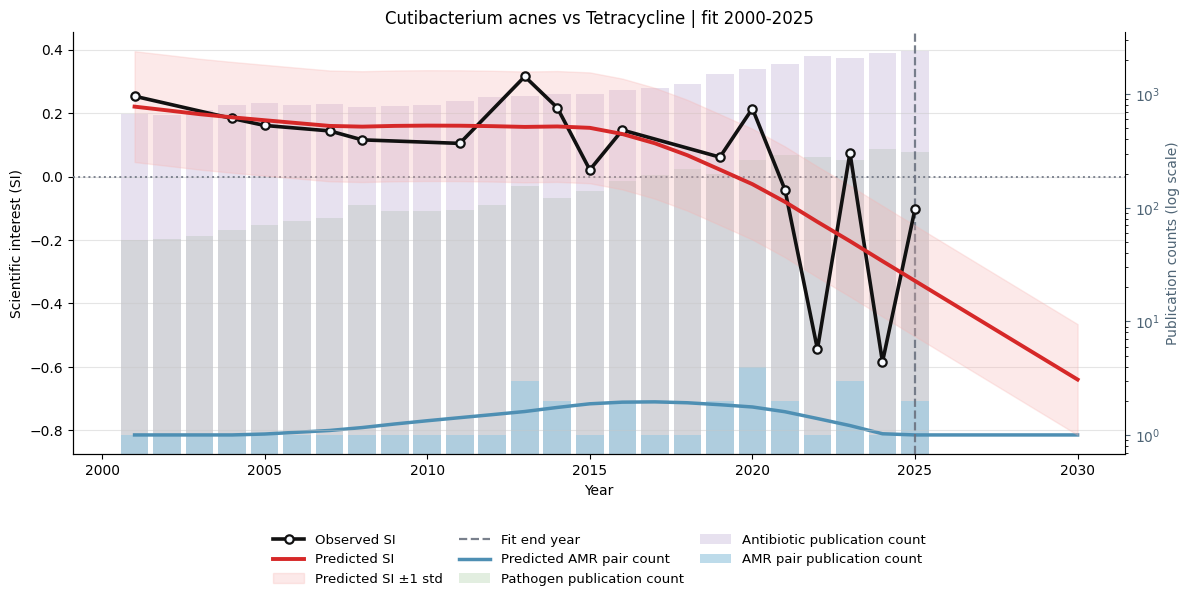

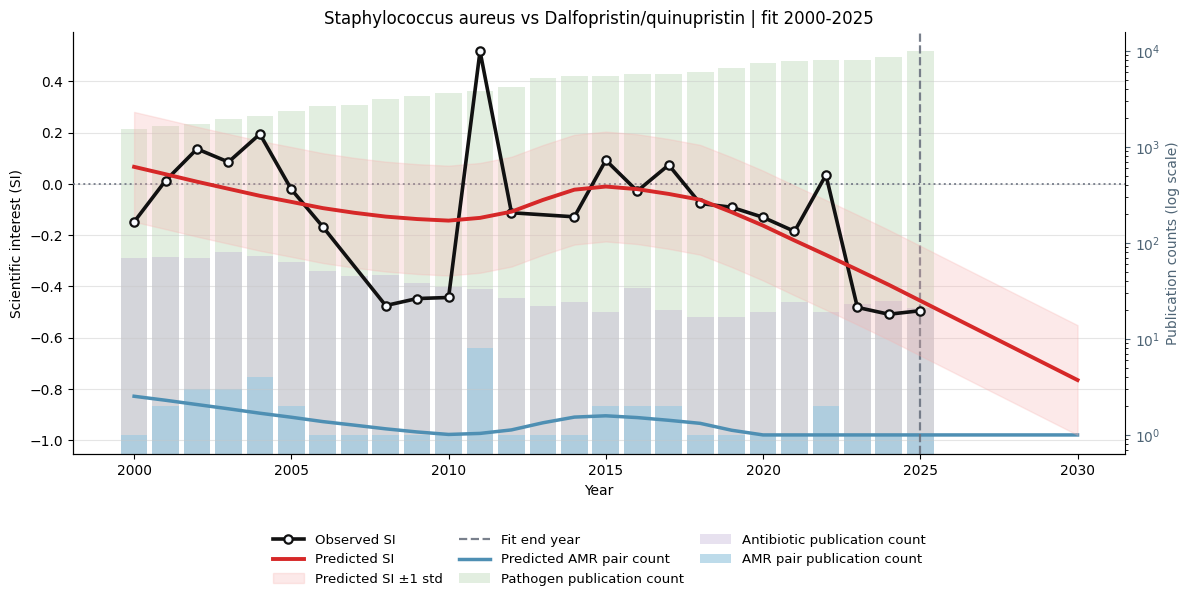

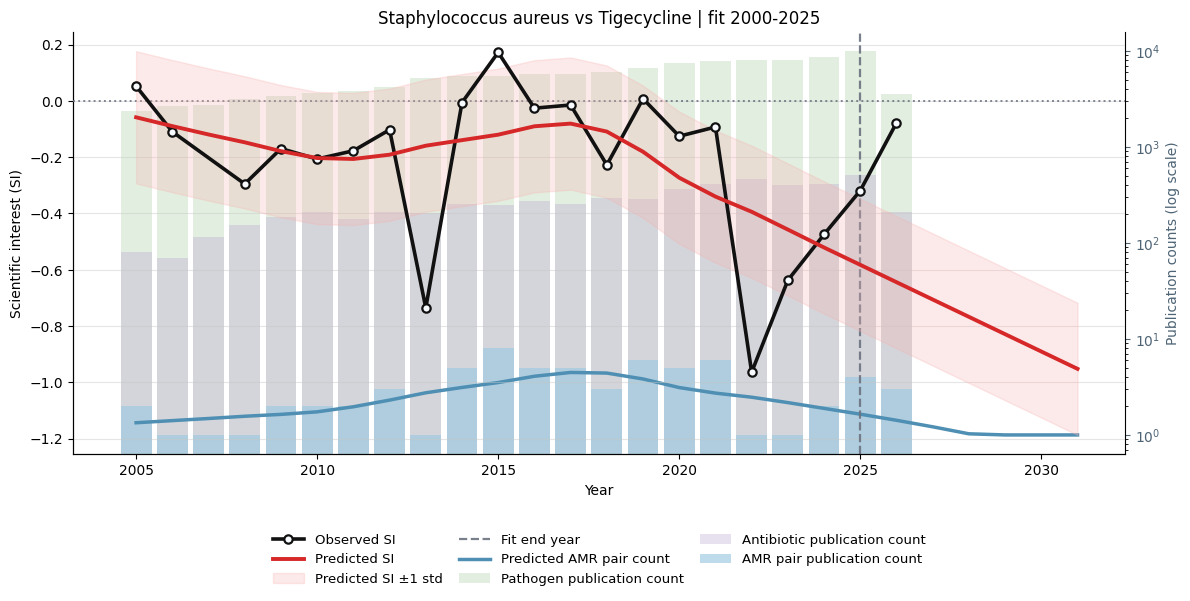

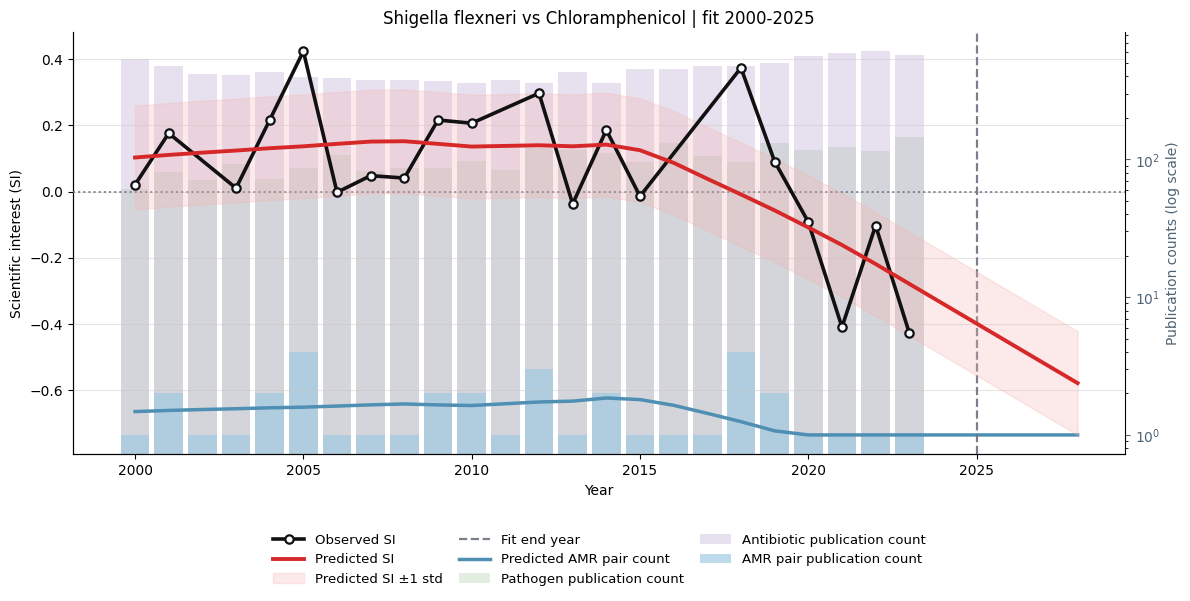

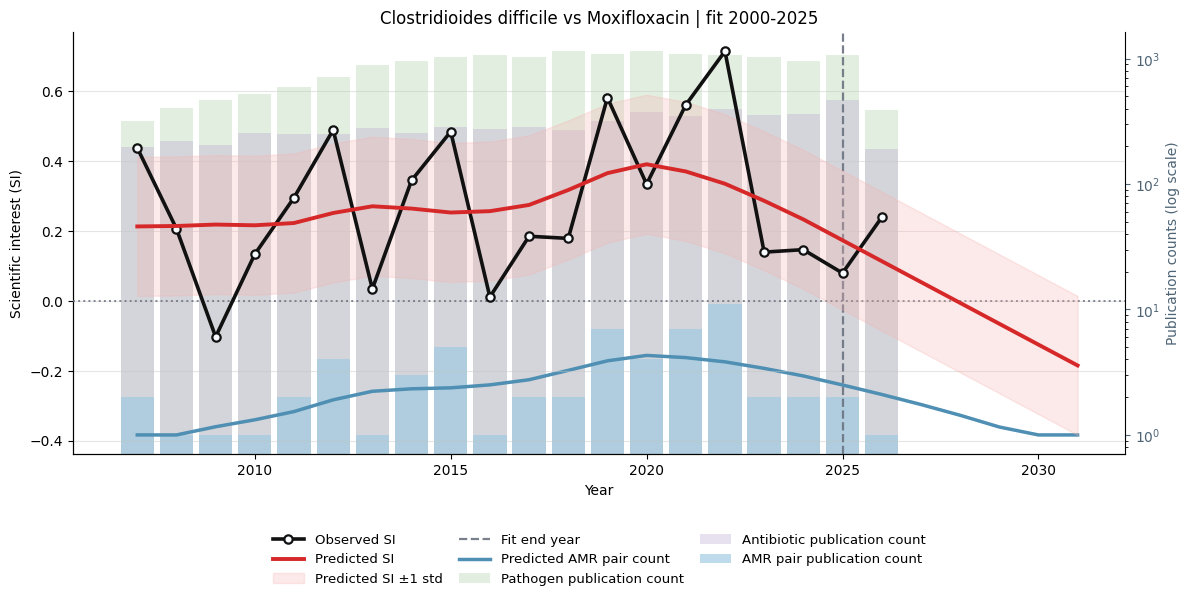

Saved 10 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/decreasing_smoothed_si_plots


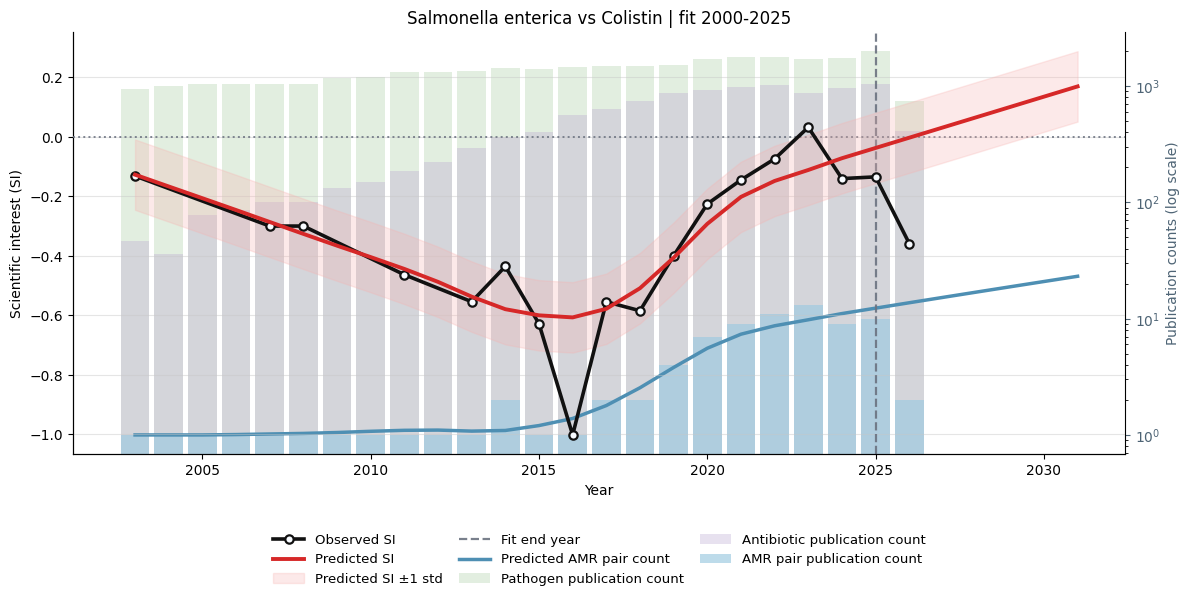

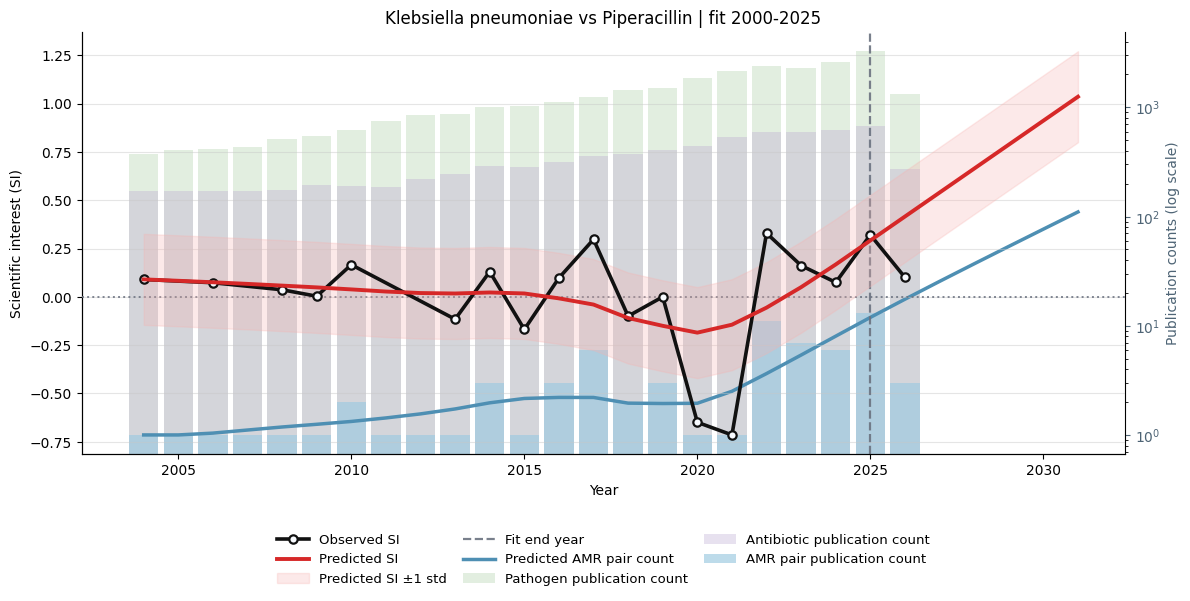

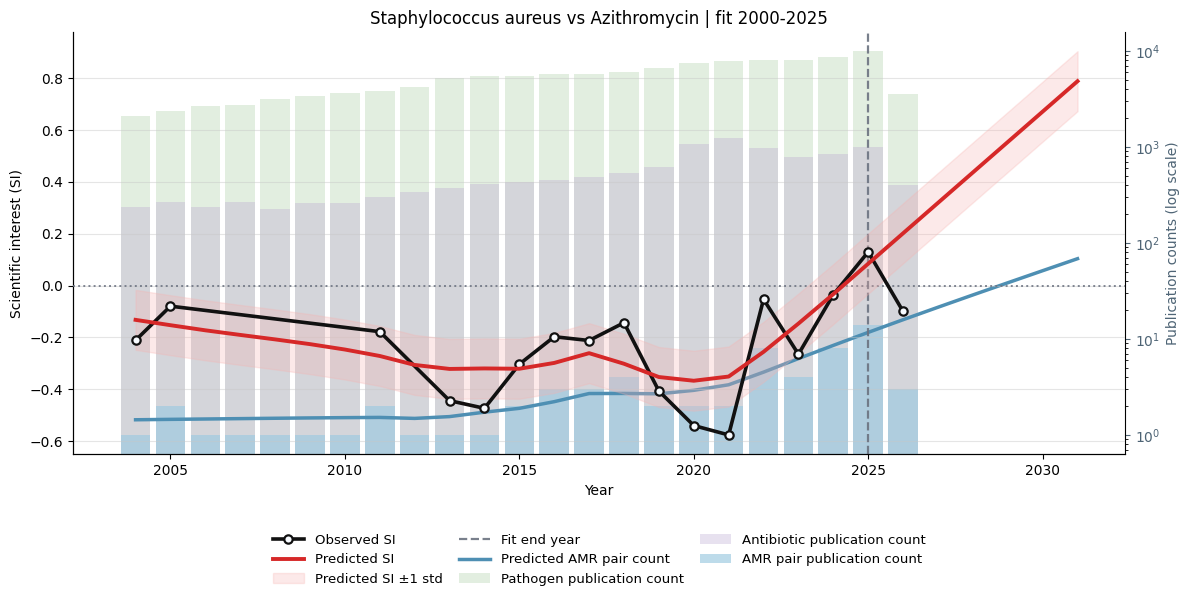

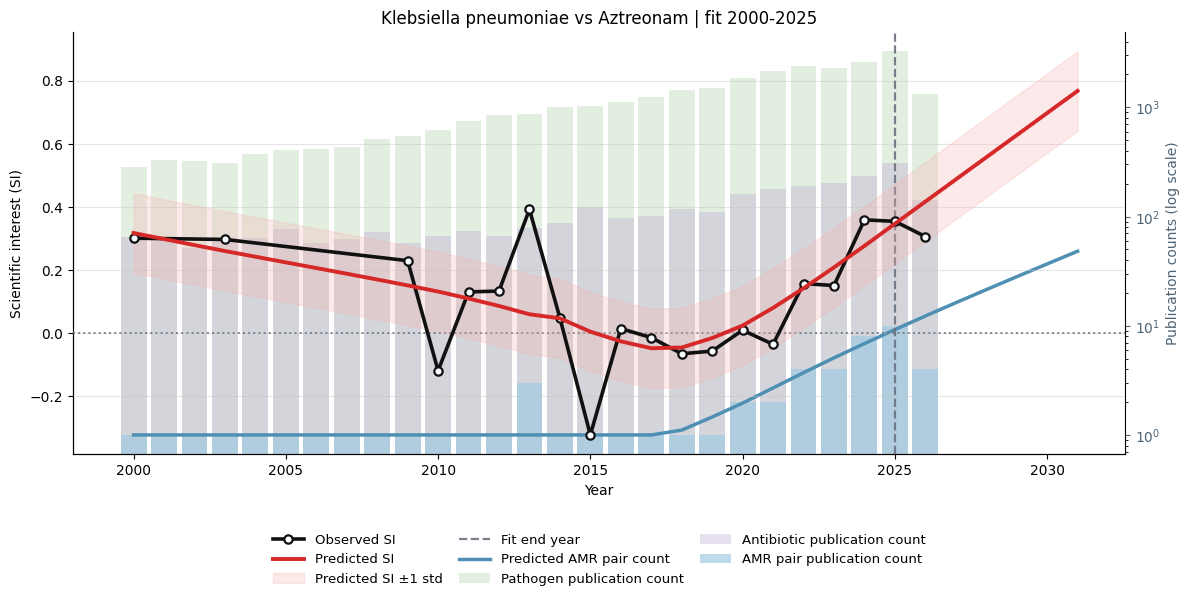

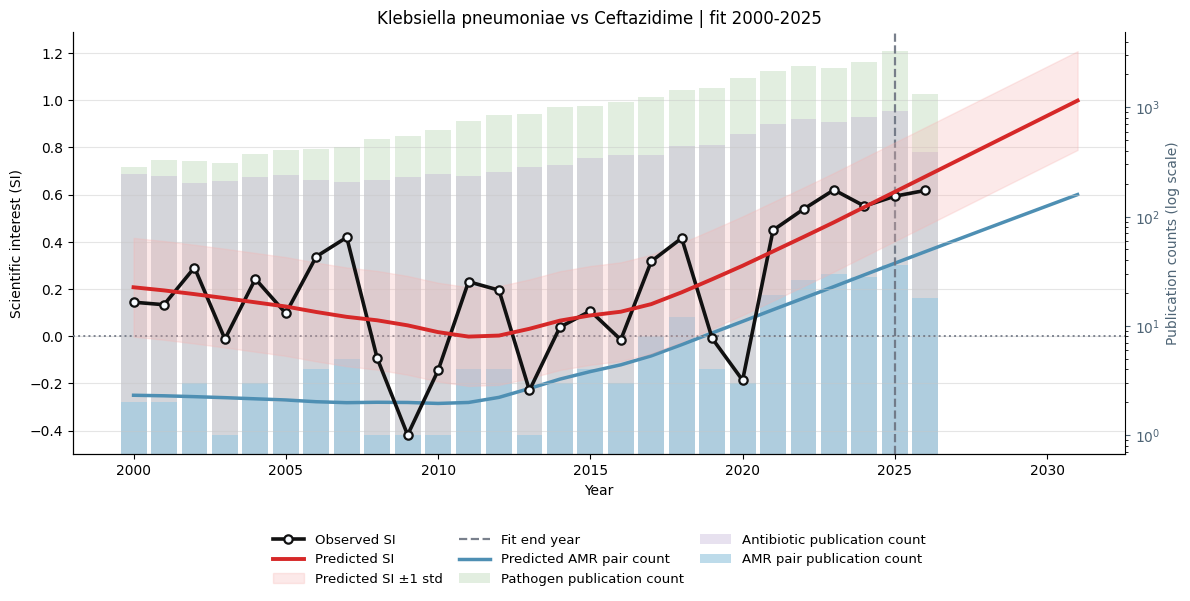

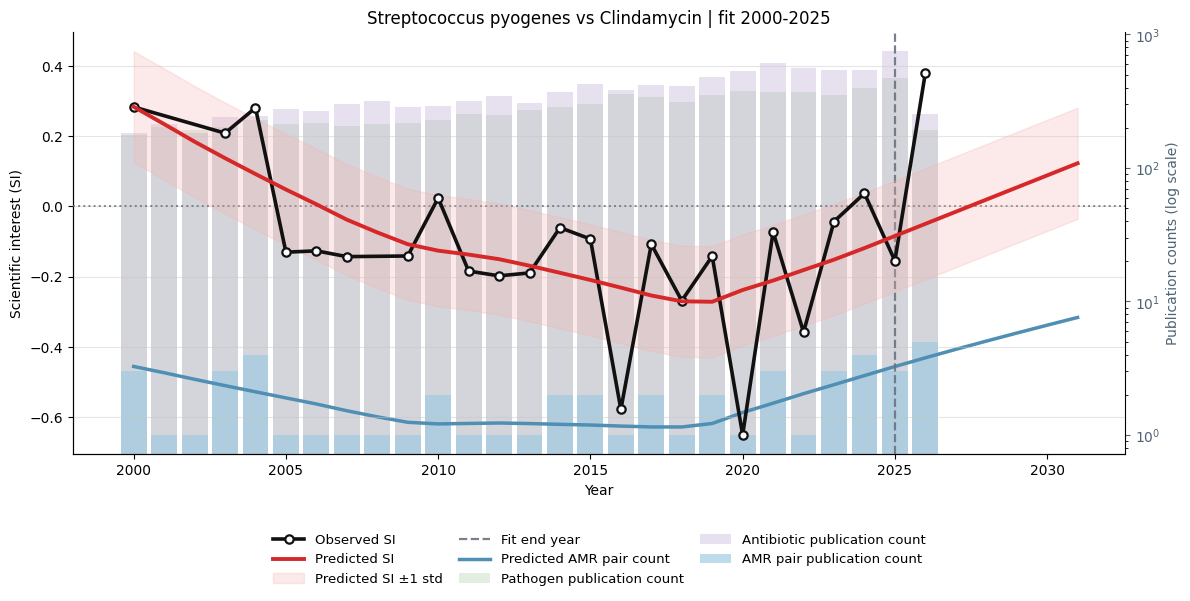

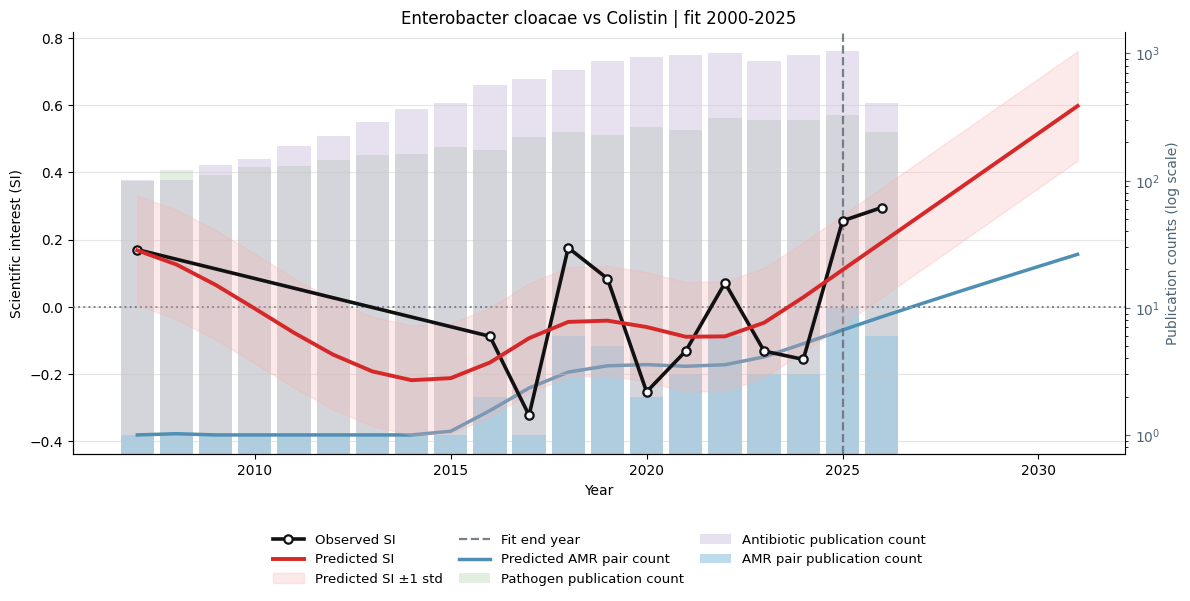

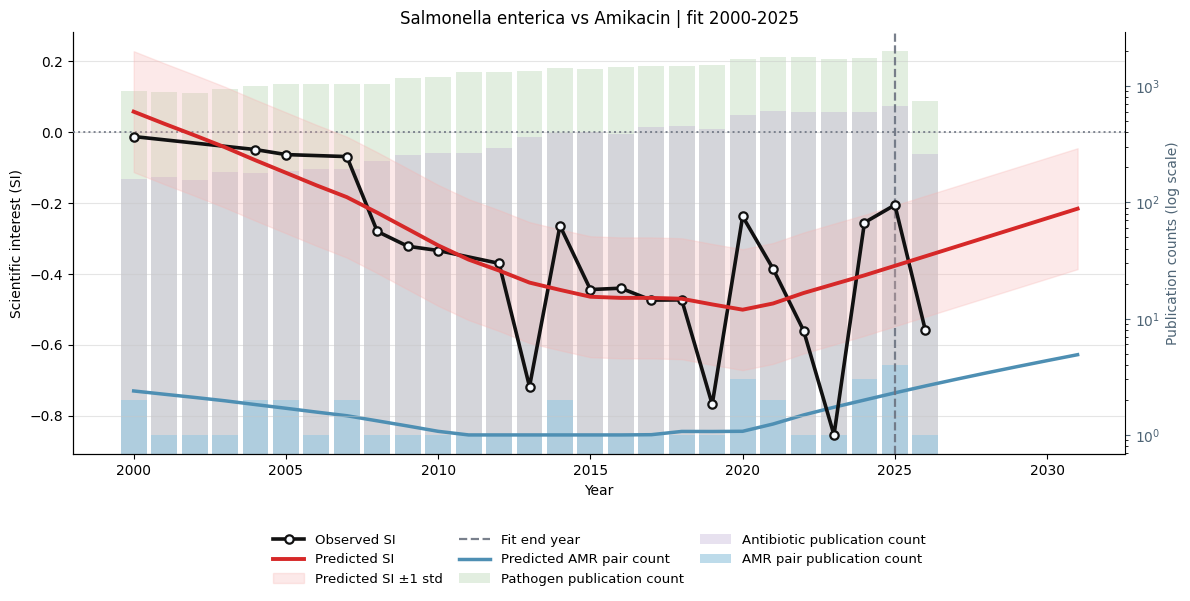

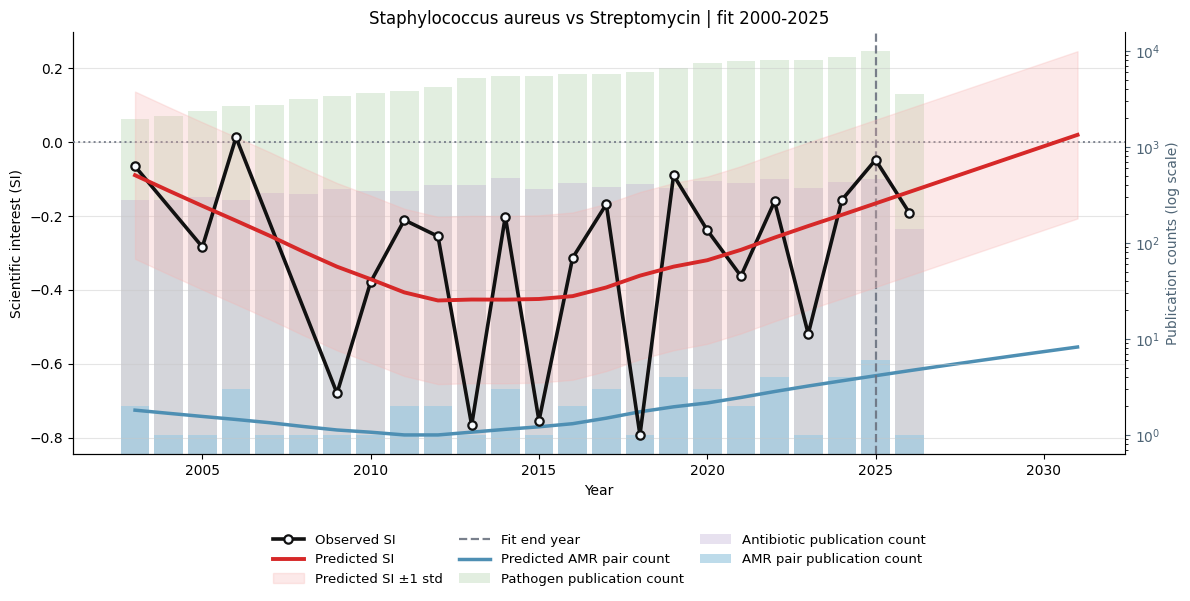

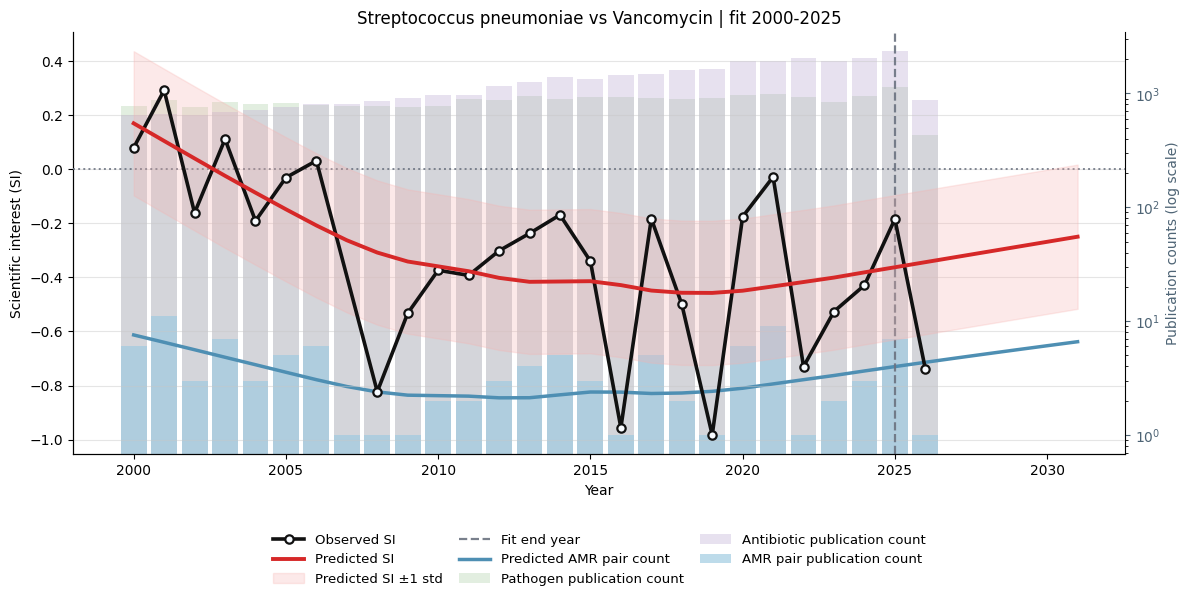

Saved 10 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/convex_u_shaped_smoothed_si_plots


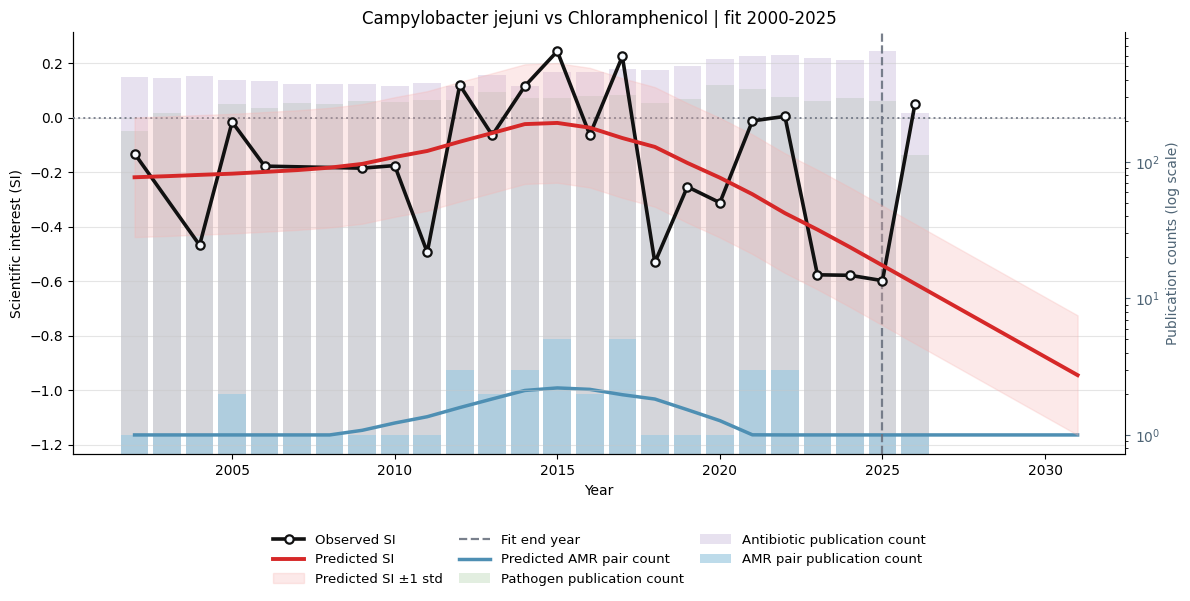

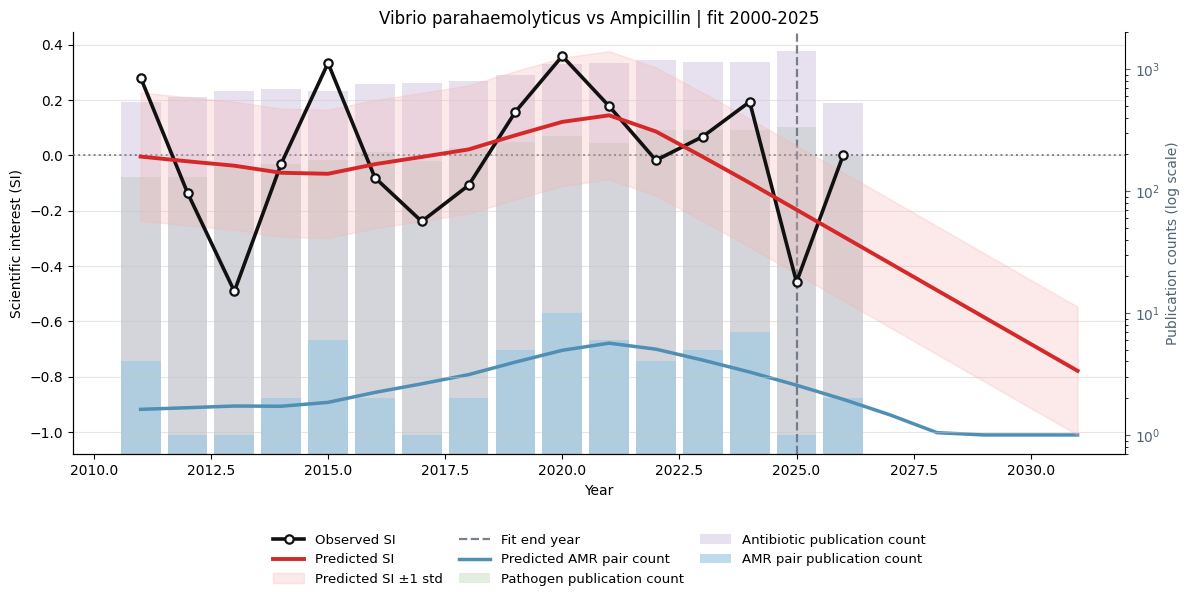

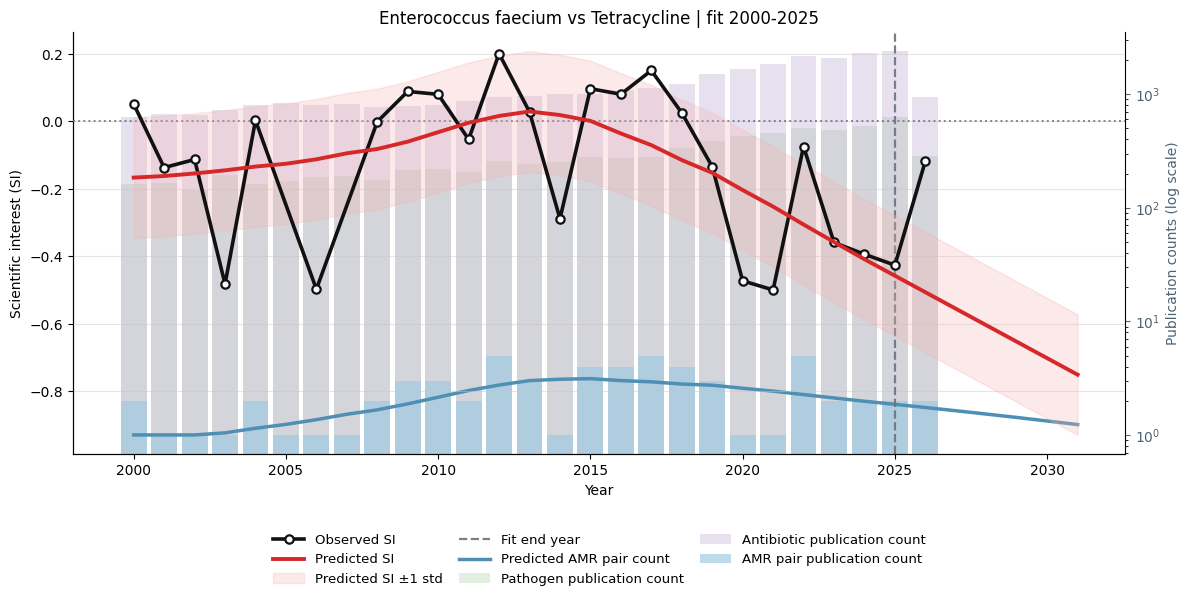

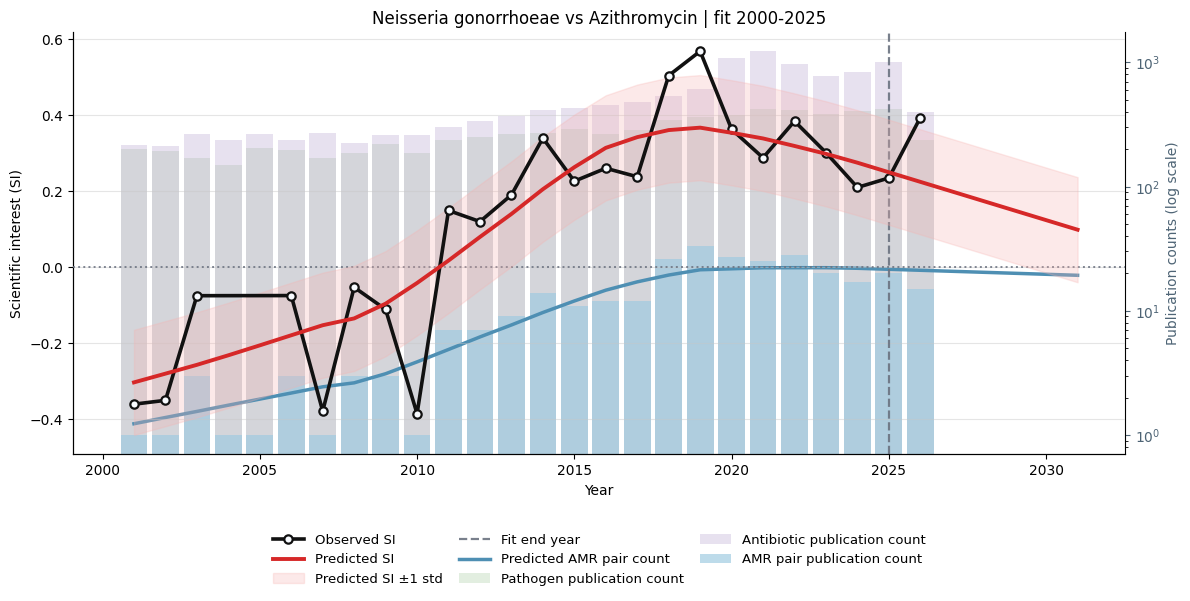

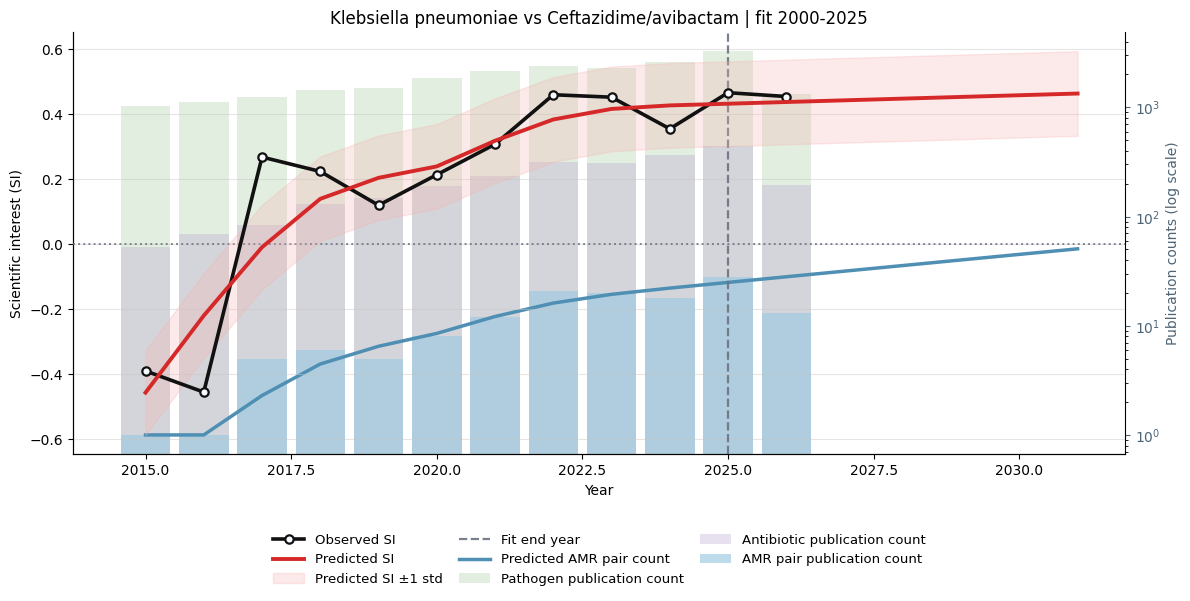

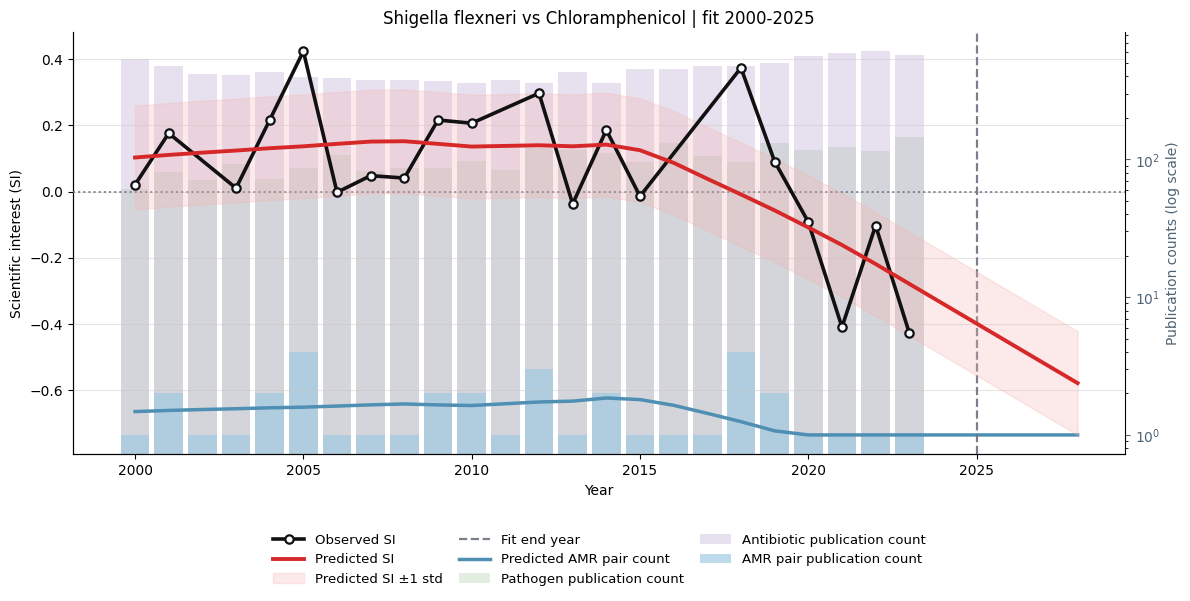

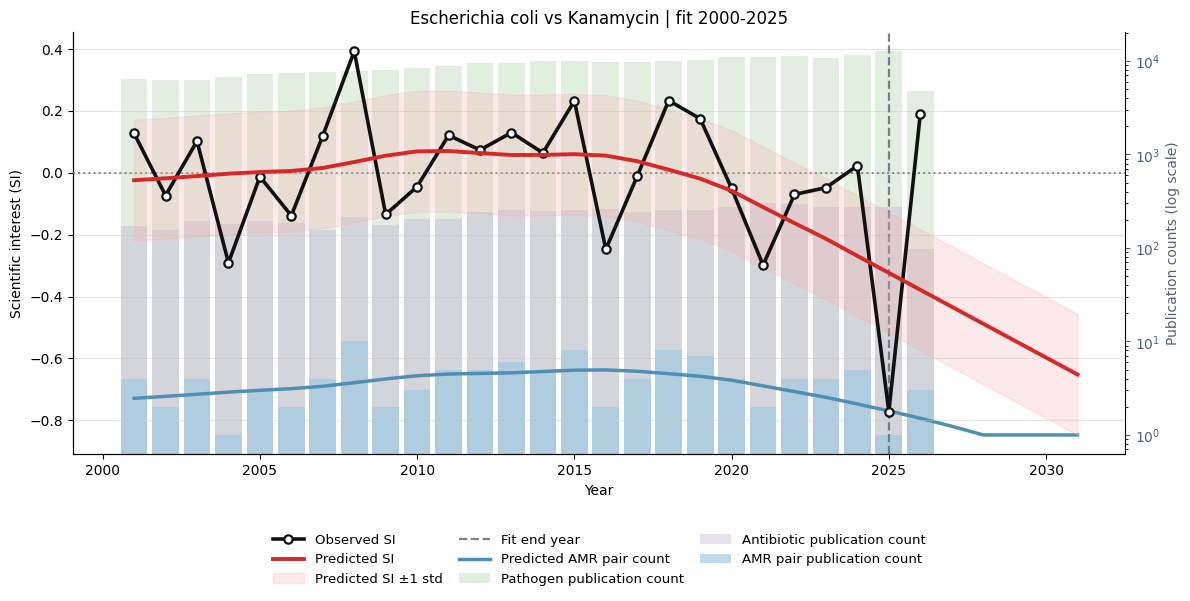

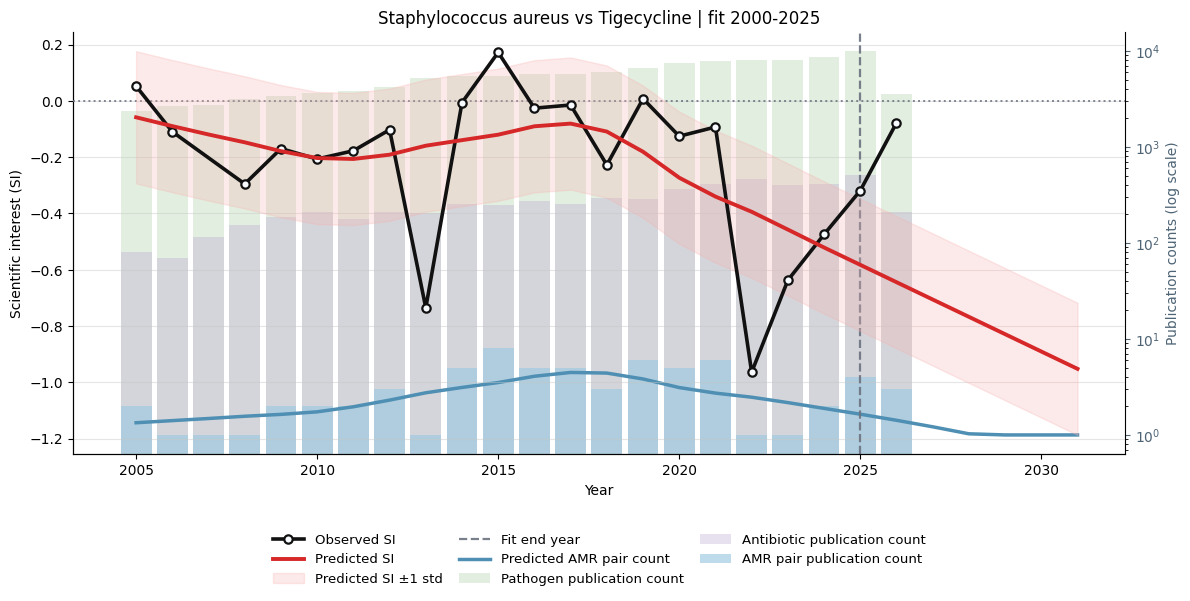

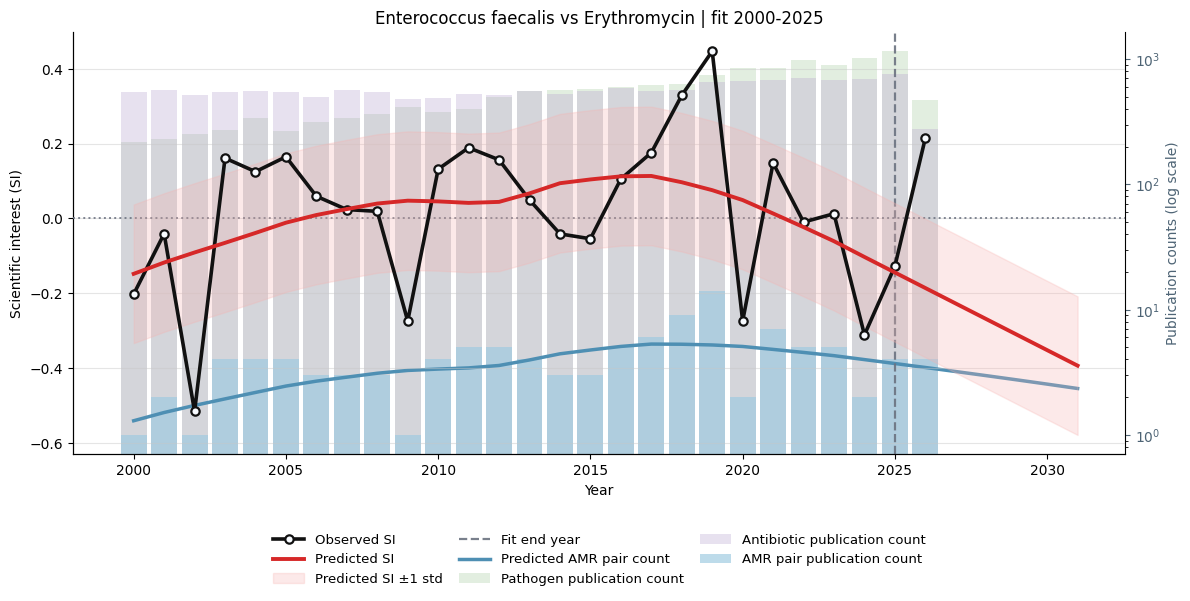

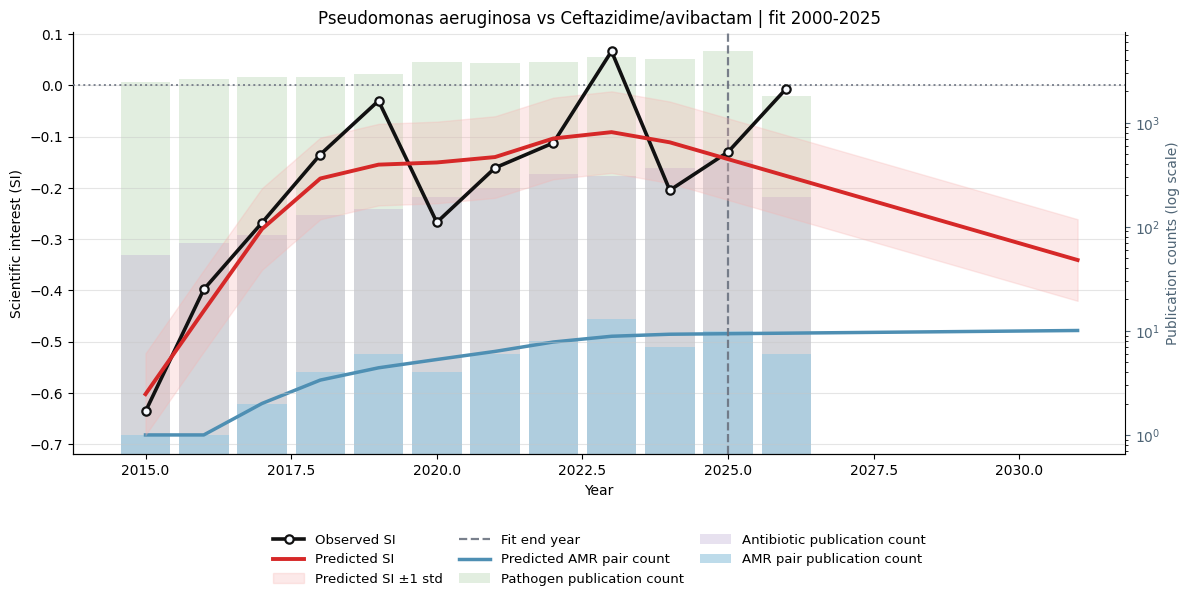

Saved 10 smoothed SI screen plots to /run/media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/outputs/figures/concave_inverted_u_smoothed_si_plots


10

In [15]:
save_smoothed_si_screen_plots(
    screen_df=decreasing_smoothed_si_df,
    si_df=si_df,
    output_dir=DECREASING_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_convex_smoothed_si_df,
    si_df=si_df,
    output_dir=CONVEX_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_concave_smoothed_si_df,
    si_df=si_df,
    output_dir=CONCAVE_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)
